# Milestone 3 — Multi-Fault Diagnosis

## Research question

Milestone 2 studied a binary task: Normal vs. Fault 4. Realistic process monitoring is harder because a system must distinguish **multiple fault types**, not just detect one known fault.

In this notebook, we compare classical machine-learning baselines with temporal models, then interpret the predictions from a chemical-engineering perspective.

**Roadmap**
1. Build a consistent multi-class dataset and chronological validation split.
2. Compare Logistic Regression and Random Forest.
3. Train a 1D CNN on overlapping time windows.
4. Convert window predictions to sample-level predictions and assess onset detection.
5. Interpret fault-specific variable signatures.
6. Analyze model errors and compare the CNN with a GRU.

**Evaluation caution:** the provided test sequences are reused across several analyses in this exploratory project. Treat test metrics as results on these particular sequences, not as a fully untouched estimate of deployment performance.

In [132]:

!git clone https://github.com/believe563/tennessee-eastman-profBraatz-database.git /content/tep_data


fatal: destination path '/content/tep_data' already exists and is not an empty directory.


In [133]:

from pathlib import Path

data_dir = Path("/content/tep_data")

train_files = sorted(data_dir.glob("d*.dat"))

print(f"Number of .dat files: {len(train_files)}")

for file in train_files:
    print(file.name)


Number of .dat files: 44
d00.dat
d00_te.dat
d01.dat
d01_te.dat
d02.dat
d02_te.dat
d03.dat
d03_te.dat
d04.dat
d04_te.dat
d05.dat
d05_te.dat
d06.dat
d06_te.dat
d07.dat
d07_te.dat
d08.dat
d08_te.dat
d09.dat
d09_te.dat
d10.dat
d10_te.dat
d11.dat
d11_te.dat
d12.dat
d12_te.dat
d13.dat
d13_te.dat
d14.dat
d14_te.dat
d15.dat
d15_te.dat
d16.dat
d16_te.dat
d17.dat
d17_te.dat
d18.dat
d18_te.dat
d19.dat
d19_te.dat
d20.dat
d20_te.dat
d21.dat
d21_te.dat


## 1. Inspect the dataset structure

Before assigning labels or training models, verify the file layout and the shape convention. Each sample should contain 52 process variables.

In [134]:
from pathlib import Path
import numpy as np

data_dir = Path("/content/tep_data")

def load_tep_data(path, expected_variables=52):
    data = np.loadtxt(path)

    if data.shape[1] == expected_variables:
        return data
    elif data.shape[0] == expected_variables:
        return data.T
    else:
        raise ValueError(
            f"Unexpected data shape {data.shape} in {path}"
        )

# Check representative files
files_to_check = [
    "d00.dat",
    "d00_te.dat",
    "d01.dat",
    "d01_te.dat",
    "d02.dat",
    "d02_te.dat",
    "d04.dat",
    "d04_te.dat",
]

for filename in files_to_check:
    data = load_tep_data(data_dir / filename)
    print(f"{filename:12s} -> shape: {data.shape}")

d00.dat      -> shape: (500, 52)
d00_te.dat   -> shape: (960, 52)
d01.dat      -> shape: (480, 52)
d01_te.dat   -> shape: (960, 52)
d02.dat      -> shape: (480, 52)
d02_te.dat   -> shape: (960, 52)
d04.dat      -> shape: (480, 52)
d04_te.dat   -> shape: (960, 52)


## 2. Construct the multi-class training dataset

We use four classes: Normal (0), Fault 1 (1), Fault 2 (2), and Fault 4 (4). Under the dataset's training-file convention, each `dXX.dat` training sequence receives the label associated with its file.

The following cell builds the feature matrix and sample labels together so their ordering remains aligned.

In [135]:
# Define the fault cases for multi-class diagnosis
train_cases = {
    0: "d00.dat",  # Normal
    1: "d01.dat",  # Fault 1
    2: "d02.dat",  # Fault 2
    4: "d04.dat",  # Fault 4
}

X_train_raw = []
y_train = []

for label, filename in train_cases.items():
    data = load_tep_data(data_dir / filename)

    X_train_raw.append(data)
    y_train.extend([label] * len(data))

X_train_raw = np.vstack(X_train_raw)
y_train = np.array(y_train)

print("X_train_raw shape:", X_train_raw.shape)
print("y_train shape:", y_train.shape)
print("\nClass counts:")

for label in sorted(np.unique(y_train)):
    print(f"Class {label}: {(y_train == label).sum()} samples")

X_train_raw shape: (1940, 52)
y_train shape: (1940,)

Class counts:
Class 0: 500 samples
Class 1: 480 samples
Class 2: 480 samples
Class 4: 480 samples


## 3. Create a chronological fitting/validation split

Adjacent process samples are temporally correlated. A random split can place near-neighbor samples in both fitting and validation sets, making validation overly optimistic. Instead, split each training sequence chronologically: the first 80% is used for fitting and the final 20% for validation.

This split is created before model fitting, and the same split is used for the classical baselines and the temporal models.

In [136]:
# Step 3: Temporal train/validation split

X_fit_list = []
y_fit_list = []

X_val_list = []
y_val_list = []

for label, filename in train_cases.items():
    data = load_tep_data(data_dir / filename)

    n_samples = len(data)
    split_idx = int(n_samples * 0.8)

    # Preserve temporal order
    X_fit_list.append(data[:split_idx])
    y_fit_list.extend([label] * split_idx)

    X_val_list.append(data[split_idx:])
    y_val_list.extend([label] * (n_samples - split_idx))

# Combine sequences
X_fit = np.vstack(X_fit_list)
y_fit = np.array(y_fit_list)

X_val = np.vstack(X_val_list)
y_val = np.array(y_val_list)

print("Training set:", X_fit.shape, y_fit.shape)
print("Validation set:", X_val.shape, y_val.shape)

print("\nTraining class counts:")
for label in sorted(np.unique(y_fit)):
    print(f"Class {label}: {(y_fit == label).sum()}")

print("\nValidation class counts:")
for label in sorted(np.unique(y_val)):
    print(f"Class {label}: {(y_val == label).sum()}")

Training set: (1552, 52) (1552,)
Validation set: (388, 52) (388,)

Training class counts:
Class 0: 400
Class 1: 384
Class 2: 384
Class 4: 384

Validation class counts:
Class 0: 100
Class 1: 96
Class 2: 96
Class 4: 96


## 4. Classical baselines: Logistic Regression and Random Forest

These two models provide complementary baselines. Logistic Regression is a relatively simple linear classifier; Random Forest can capture nonlinear relationships. We first compare them on the chronological validation set, then evaluate their predictions on the supplied test sequences.

In [137]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# Define models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        )),
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
}

# Train and evaluate
results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_fit, y_fit)

    y_pred = model.predict(X_val)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision (macro)": precision_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "F1 (macro)": f1_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
    })

    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print("\nClassification report:")
    print(classification_report(
        y_val,
        y_pred,
        labels=[0, 1, 2, 4],
        target_names=["Normal", "Fault 1", "Fault 2", "Fault 4"],
        zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(y_val, y_pred, labels=[0, 1, 2, 4]))

# Summary table
results_df = pd.DataFrame(results)
display(results_df.round(4))


Logistic Regression

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       100
     Fault 1       1.00      1.00      1.00        96
     Fault 2       1.00      1.00      1.00        96
     Fault 4       1.00      1.00      1.00        96

    accuracy                           1.00       388
   macro avg       1.00      1.00      1.00       388
weighted avg       1.00      1.00      1.00       388

Confusion matrix:
[[100   0   0   0]
 [  0  96   0   0]
 [  0   0  96   0]
 [  0   0   0  96]]

Random Forest

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       100
     Fault 1       1.00      1.00      1.00        96
     Fault 2       1.00      1.00      1.00        96
     Fault 4       1.00      1.00      1.00        96

    accuracy                           1.00       388
   macro avg       1.00      1.00      1.00       388
weight

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0


Both classical models score very highly on the validation split. That is encouraging, but validation performance alone does not tell us whether the result holds on the separate test files. The next cells construct the multi-class test set and compare both models using the same labels and class order.

In [138]:
# Step 5-1: Build the independent test dataset

test_cases = {
    0: "d00_te.dat",
    1: "d01_te.dat",
    2: "d02_te.dat",
    4: "d04_te.dat",
}

X_test_list = []
y_test_list = []

for label, filename in test_cases.items():
    data = load_tep_data(data_dir / filename)

    if label == 0:
        # Normal test sequence: all samples are normal
        labels = np.zeros(len(data), dtype=int)
    else:
        # Fault test sequence:
        # first 160 samples are normal,
        # remaining samples belong to the corresponding fault
        labels = np.full(len(data), label, dtype=int)
        labels[:160] = 0

    X_test_list.append(data)
    y_test_list.append(labels)

X_test = np.vstack(X_test_list)
y_test = np.concatenate(y_test_list)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTest class counts:")
for label in sorted(np.unique(y_test)):
    print(f"Class {label}: {(y_test == label).sum()}")

X_test shape: (3840, 52)
y_test shape: (3840,)

Test class counts:
Class 0: 1440
Class 1: 800
Class 2: 800
Class 4: 800


### 4.1 Evaluate the classical baselines on the test sequences

We report accuracy, macro F1, class-wise metrics, and confusion matrices. Macro F1 gives each class equal weight, which is useful when class supports differ.

In [139]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
import pandas as pd

class_labels = [0, 1, 2, 4]
class_names = ["Normal", "Fault 1", "Fault 2", "Fault 4"]

test_results = []

for name, model in trained_models.items():
    # Predict only: do not fit on test data
    y_pred = model.predict(X_test)

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(
            y_test, y_pred, labels=class_labels,
            average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_test, y_pred, labels=class_labels,
            average="macro", zero_division=0
        ),
        "F1 (macro)": f1_score(
            y_test, y_pred, labels=class_labels,
            average="macro", zero_division=0
        ),
    })

    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print("\nClassification report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        zero_division=0,
    ))

    print("Confusion matrix:")
    print(confusion_matrix(
        y_test, y_pred, labels=class_labels
    ))

test_results_df = pd.DataFrame(test_results)
display(test_results_df.round(4))


Logistic Regression

Classification report:
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99      1440
     Fault 1       1.00      0.99      1.00       800
     Fault 2       0.98      0.98      0.98       800
     Fault 4       1.00      1.00      1.00       800

    accuracy                           0.99      3840
   macro avg       0.99      0.99      0.99      3840
weighted avg       0.99      0.99      0.99      3840

Confusion matrix:
[[1425    1   14    0]
 [   4  796    0    0]
 [  16    0  784    0]
 [   0    0    0  800]]

Random Forest

Classification report:
              precision    recall  f1-score   support

      Normal       0.99      0.95      0.97      1440
     Fault 1       1.00      1.00      1.00       800
     Fault 2       0.92      0.98      0.95       800
     Fault 4       1.00      1.00      1.00       800

    accuracy                           0.98      3840
   macro avg       0.98      0.98      0.98 

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Logistic Regression,0.9909,0.9918,0.9911,0.9915
1,Random Forest,0.9789,0.9779,0.9840,0.9806


### Interpretation: where do the classical models make mistakes?

The confusion matrices show which classes are being confused, not just the overall score. Keep in mind that these are results on the supplied sequences; they do not by themselves establish performance on new process runs.

Logistic regression's accuracy is better by 1.20 percent points. The pattern shown in the confusion matrix is that:
- Fault 4: Both models got all 800 correctly.
- Fault 1: Logistic Regression got 796/800, while Random Forest got 798/800.
- Fault 2: Logistic Regression got 784/800, while Random Forest got 788/800.
- Normal: Random Forest misclassified 67/1440 normal samples as Fault 2. Logistic Regression made the same error for 14 sampels.

Hence, Ranfom Forest was better on detecting Fault 1 and Fault 2, but this was outweighted by its problem of misclassifying even the normal ones as Fault 1 and Fault 2.


## 5. Interpret the classical model: feature importance and class distributions

Model performance tells us whether classification works; it does not explain which variables carry predictive information. Random Forest feature importance is used here to nominate variables for closer inspection.

**Important distinction:** feature importance indicates predictive usefulness within this fitted model. It does not prove that a variable causes a fault.

In [140]:
# Step 6A: Random Forest feature importance

import pandas as pd

feature_names = (
    [f"xmeas_{i}" for i in range(1, 42)]
    + [f"xmv_{i}" for i in range(1, 12)]
)

rf_model = trained_models["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_,
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(5))

,Feature,Importance
50,xmv_10,0.25568
0,xmeas_1,0.07164
46,xmv_6,0.06992
43,xmv_3,0.06491
17,xmeas_18,0.05816
9,xmeas_10,0.05046
33,xmeas_34,0.04959
3,xmeas_4,0.04806
27,xmeas_28,0.04423
49,xmv_9,0.03652


Three points worth noting down:
- xmv_10 has the highest importance with 0.25568.
- Out of the top 15, 10 are measured variables(xmeas), and 5 are manipulated variables(xmv).
- Random Forest misclassified some normal samples as Fault 2.

Next, we should compare how the important variables above get changed in the Normal, Fault 1, Fault 2, and Fault 4 scenarios. This way, we can tell which variables are responsible for classifying which faults.

In [141]:
# Step 6B: Compare feature distributions across classes

top_features = [
    "xmv_10",
    "xmeas_1",
    "xmv_6",
    "xmv_3",
    "xmeas_18",
    "xmeas_10",
    "xmeas_34",
    "xmeas_4",
]

feature_to_idx = {
    name: i for i, name in enumerate(feature_names)
}

summary_rows = []

for label in [0, 1, 2, 4]:
    class_data = X_train_raw[y_train == label]

    for feature in top_features:
        idx = feature_to_idx[feature]
        values = class_data[:, idx]

        summary_rows.append({
            "Class": label,
            "Feature": feature,
            "Mean": values.mean(),
            "Std": values.std(),
        })

feature_summary = pd.DataFrame(summary_rows)

display(
    feature_summary.pivot(
        index="Feature",
        columns="Class",
        values="Mean"
    ).round(3)
)

print("\nStandard deviation by class:")
display(
    feature_summary.pivot(
        index="Feature",
        columns="Class",
        values="Std"
    ).round(3)
)

Class,0,1,2,4
Feature,,,,
xmeas_1,0.251,0.758,0.282,0.250
xmeas_10,0.338,0.318,0.680,0.337
xmeas_18,65.721,68.350,63.314,65.845
xmeas_34,2.259,2.304,1.603,2.266
xmeas_4,9.344,8.794,9.615,9.346
xmv_10,41.095,40.979,41.449,44.906
xmv_3,24.721,74.617,27.726,24.622
xmv_6,40.082,37.818,80.859,40.004



Standard deviation by class:


Class,0,1,2,4
Feature,,,,
xmeas_1,0.029,0.125,0.034,0.029
xmeas_10,0.012,0.028,0.091,0.013
xmeas_18,0.342,1.834,1.113,0.287
xmeas_34,0.026,0.066,0.286,0.025
xmeas_4,0.076,0.276,0.107,0.080
xmv_10,0.525,0.867,0.571,0.493
xmv_3,2.822,12.297,3.362,2.816
xmv_6,1.437,3.381,10.937,1.556


Next, we should visualise time-series for each fault and understand how the model calssifies each fault.

### 5.1 From important variables to process signatures

We now inspect selected variables over time. The aim is not to create a separate model for each variable, but to understand whether the model's useful features correspond to visible, fault-specific patterns in the process data.

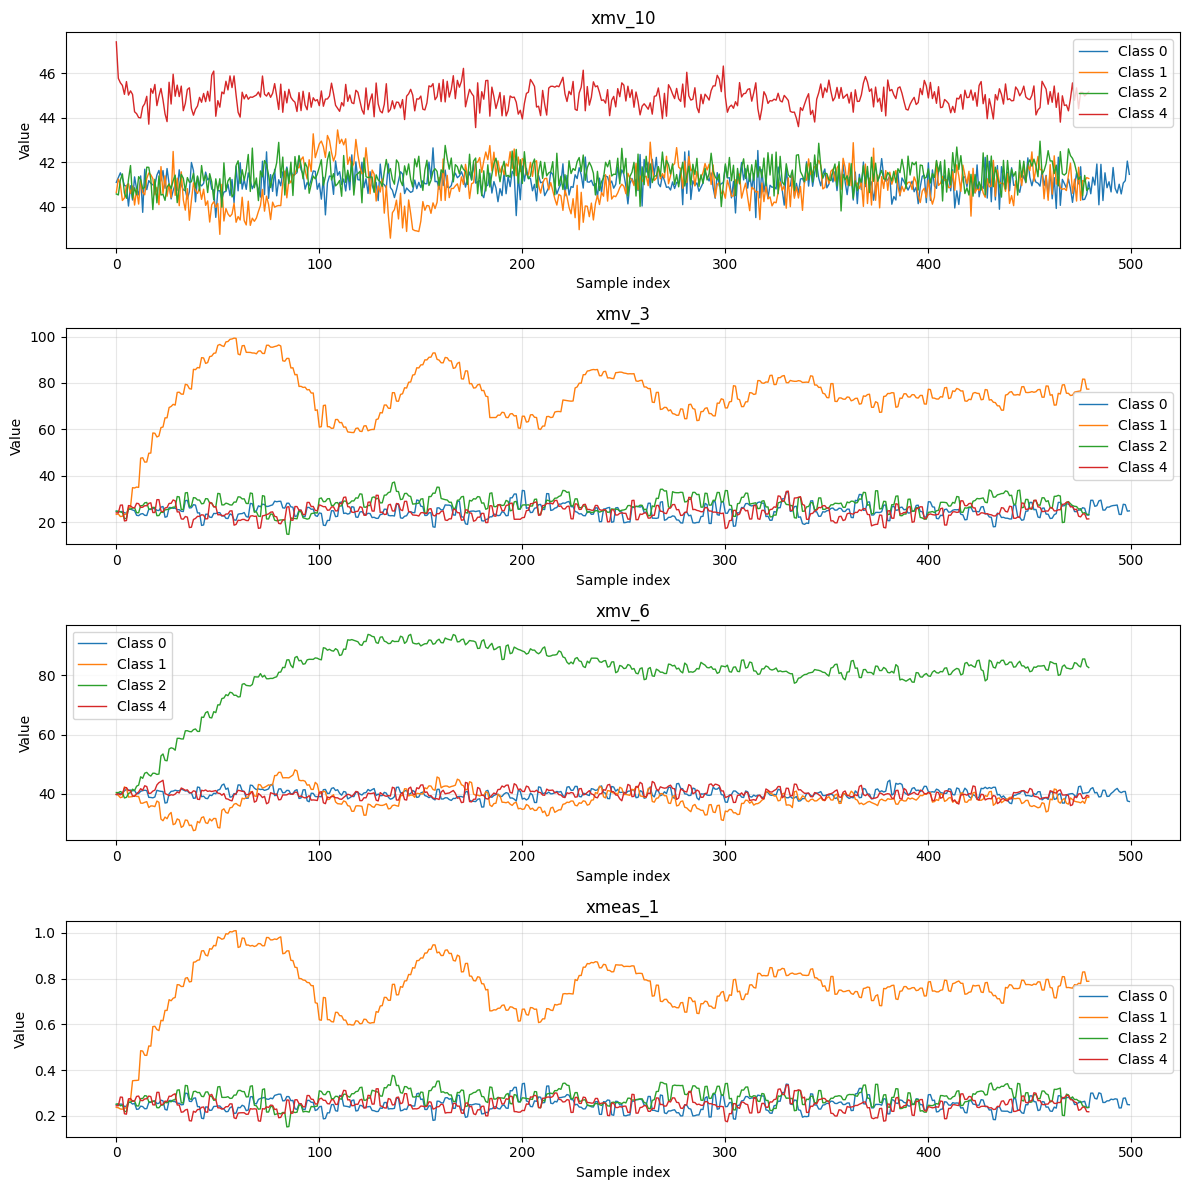

In [86]:

import matplotlib.pyplot as plt

# Selected variables
selected_features = [
    "xmv_10",
    "xmv_3",
    "xmv_6",
    "xmeas_1",
]

feature_to_idx = {
    name: i for i, name in enumerate(feature_names)
}

# Use training sequences for exploratory analysis
fig, axes = plt.subplots(
    len(selected_features), 1,
    figsize=(12, 12)
)

for ax, feature in zip(axes, selected_features):
    idx = feature_to_idx[feature]

    for label, filename in train_cases.items():
        data = load_tep_data(data_dir / filename)

        ax.plot(
            np.arange(len(data)),
            data[:, idx],
            label=f"Class {label}",
            linewidth=1
        )

    ax.set_title(feature)
    ax.set_xlabel("Sample index")
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Interim observation: candidate signatures

The selected time-series plots suggest different candidate signatures for the faults: `xmv_3` for Fault 1, `xmv_6` and `xmeas_10` for Fault 2, and `xmv_10` for Fault 4. These are descriptive patterns in the observed sequences, not causal conclusions.

This motivates a temporal model: if fault signatures evolve over time, can a model that sees a short sequence classify windows effectively?

While the 2D CNN learns spatial apttern of an image, the 1D CNN learns repetitive patterns across the time axis.

First, we should create the time-series window. Let't start with window size = 50, stride = 5. This means somehting like this:
- Window 1: sample 0–49
- Window 2: sample 5–54
- Window 3: sample 10–59
We will split each training sequence 80:20 chronologically before making the windows, so that the training and validation windows would not overlap.

In [87]:
# Step 8A: Create time-series windows for 1D CNN

import numpy as np
from sklearn.preprocessing import StandardScaler

WINDOW_SIZE = 50
STRIDE = 5

train_windows = []
train_window_labels = []

val_windows = []
val_window_labels = []

# Keep the temporal split within each original sequence
scaler = StandardScaler()

# Fit scaler only on the training portions
fit_segments = {}

for label, filename in train_cases.items():
    data = load_tep_data(data_dir / filename)

    split_idx = int(len(data) * 0.8)
    fit_segments[label] = data[:split_idx]

scaler.fit(np.vstack(list(fit_segments.values())))

def make_windows(data, label, window_size=50, stride=5):
    windows = []
    labels = []

    for start in range(0, len(data) - window_size + 1, stride):
        window = data[start:start + window_size]
        windows.append(window)
        labels.append(label)

    return windows, labels

for label, filename in train_cases.items():
    data = load_tep_data(data_dir / filename)
    split_idx = int(len(data) * 0.8)

    # Split first, then scale using training-fitted statistics
    fit_data = scaler.transform(data[:split_idx])
    val_data = scaler.transform(data[split_idx:])

    # Create windows separately to avoid crossing the split boundary
    Xw_train, yw_train = make_windows(
        fit_data, label, WINDOW_SIZE, STRIDE
    )
    Xw_val, yw_val = make_windows(
        val_data, label, WINDOW_SIZE, STRIDE
    )

    train_windows.extend(Xw_train)
    train_window_labels.extend(yw_train)

    val_windows.extend(Xw_val)
    val_window_labels.extend(yw_val)

X_cnn_train = np.array(train_windows, dtype=np.float32)
y_cnn_train = np.array(train_window_labels, dtype=np.int64)

X_cnn_val = np.array(val_windows, dtype=np.float32)
y_cnn_val = np.array(val_window_labels, dtype=np.int64)

print("CNN training windows:", X_cnn_train.shape)
print("CNN training labels:", y_cnn_train.shape)
print("CNN validation windows:", X_cnn_val.shape)
print("CNN validation labels:", y_cnn_val.shape)

print("\nTraining windows per class:")
for label in [0, 1, 2, 4]:
    print(label, np.sum(y_cnn_train == label))

print("\nValidation windows per class:")
for label in [0, 1, 2, 4]:
    print(label, np.sum(y_cnn_val == label))

CNN training windows: (272, 50, 52)
CNN training labels: (272,)
CNN validation windows: (41, 50, 52)
CNN validation labels: (41,)

Training windows per class:
0 71
1 67
2 67
4 67

Validation windows per class:
0 11
1 10
2 10
4 10


## 6. Temporal classification with a 1D CNN

A sample-wise classifier treats every row independently. A 1D CNN instead receives a window of consecutive samples and can learn local temporal patterns.

We use a 50-sample window and stride 5. Overlapping windows increase the number of training examples, but they are correlated; validation results should therefore be interpreted cautiously.

Let's make the first 1D CNN.

Input
- (Batch, 52, 50)

Conv1d + ReLU
- 52 channels → 32 channels

MaxPool1d
- Time length 50 → 25

Flatten + Linear
- 4 class logits output

In [88]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

# Original shape: (samples, time steps, variables)
# Conv1d expects: (samples, channels, time steps)

X_train_t = torch.tensor(
    X_cnn_train.transpose(0, 2, 1),
    dtype=torch.float32
)
X_val_t = torch.tensor(
    X_cnn_val.transpose(0, 2, 1),
    dtype=torch.float32
)

# Convert original labels {0, 1, 2, 4} to {0, 1, 2, 3}
label_to_index = {0: 0, 1: 1, 2: 2, 4: 3}
index_to_label = {v: k for k, v in label_to_index.items()}

y_train_idx = np.array(
    [label_to_index[y] for y in y_cnn_train]
)
y_val_idx = np.array(
    [label_to_index[y] for y in y_cnn_val]
)

y_train_t = torch.tensor(y_train_idx, dtype=torch.long)
y_val_t = torch.tensor(y_val_idx, dtype=torch.long)

print("X_train_t:", X_train_t.shape)
print("X_val_t:", X_val_t.shape)
print("y_train_t:", y_train_t.shape)
print("y_val_t:", y_val_t.shape)

X_train_t: torch.Size([272, 52, 50])
X_val_t: torch.Size([41, 52, 50])
y_train_t: torch.Size([272])
y_val_t: torch.Size([41])


### 6.1 Define the CNN architecture

The network applies temporal convolutions and pooling, then maps the learned representation to four class logits. The output class indices are encoded separately from the original labels `{0, 1, 2, 4}`.

In [89]:
class TEP_CNN(nn.Module):
    def __init__(self, num_variables=52, num_classes=4):
        super().__init__()

        self.conv1 = nn.Conv1d(
            in_channels=num_variables,
            out_channels=32,
            kernel_size=5,
            padding=2
        )

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2)

        self.fc = nn.Linear(32 * 25, num_classes)

    def forward(self, x):
        x = self.conv1(x)  # (batch, 32, 50)
        x = self.relu(x)
        x = self.pool(x)   # (batch, 32, 25)

        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)     # (batch, 4)

        return x


cnn_model = TEP_CNN()

print(cnn_model)
print("\nTotal parameters:",
      sum(p.numel() for p in cnn_model.parameters()))

TEP_CNN(
  (conv1): Conv1d(52, 32, kernel_size=(5,), stride=(1,), padding=(2,))
  (relu): ReLU()
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=800, out_features=4, bias=True)
)

Total parameters: 11556


### 6.2 Build data loaders

The data loaders package the window tensors and their labels into batches for training. Training batches are shuffled; validation batches are not used to update model parameters.

In [90]:
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 9
Validation batches: 2


### 6.3 Configure the loss and optimizer

Cross-entropy loss is appropriate for multi-class classification. Adam updates the CNN parameters using the training windows.

In [91]:
import torch.optim as optim

# Loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

# Optimizer updates model parameters
optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

### 6.4 Train the CNN

We track training loss and validation loss/metrics over epochs. Validation is used to monitor learning, not to update model weights directly.

In [92]:
# Step 8D: Train the CNN

from sklearn.metrics import accuracy_score, f1_score

EPOCHS = 50

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
}

for epoch in range(EPOCHS):

    # ----- Training -----
    cnn_model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        logits = cnn_model(X_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(X_batch)

    train_loss = running_loss / len(train_dataset)

    # ----- Validation -----
    cnn_model.eval()
    val_running_loss = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            logits = cnn_model(X_batch)
            loss = criterion(logits, y_batch)

            val_running_loss += loss.item() * len(X_batch)

            predictions = logits.argmax(dim=1)

            val_predictions.extend(predictions.cpu().numpy())
            val_targets.extend(y_batch.cpu().numpy())

    val_loss = val_running_loss / len(val_dataset)
    val_accuracy = accuracy_score(val_targets, val_predictions)
    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro",
        zero_division=0,
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_macro_f1"].append(val_macro_f1)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f} | "
            f"Val Macro F1: {val_macro_f1:.4f}"
        )

Epoch 01/50 | Train Loss: 0.9851 | Val Loss: 0.5220 | Val Acc: 0.9756 | Val Macro F1: 0.9762
Epoch 05/50 | Train Loss: 0.0130 | Val Loss: 0.0107 | Val Acc: 1.0000 | Val Macro F1: 1.0000
Epoch 10/50 | Train Loss: 0.0017 | Val Loss: 0.0030 | Val Acc: 1.0000 | Val Macro F1: 1.0000
Epoch 15/50 | Train Loss: 0.0010 | Val Loss: 0.0020 | Val Acc: 1.0000 | Val Macro F1: 1.0000
Epoch 20/50 | Train Loss: 0.0006 | Val Loss: 0.0014 | Val Acc: 1.0000 | Val Macro F1: 1.0000
Epoch 25/50 | Train Loss: 0.0005 | Val Loss: 0.0011 | Val Acc: 1.0000 | Val Macro F1: 1.0000
Epoch 30/50 | Train Loss: 0.0004 | Val Loss: 0.0008 | Val Acc: 1.0000 | Val Macro F1: 1.0000
Epoch 35/50 | Train Loss: 0.0003 | Val Loss: 0.0007 | Val Acc: 1.0000 | Val Macro F1: 1.0000
Epoch 40/50 | Train Loss: 0.0002 | Val Loss: 0.0006 | Val Acc: 1.0000 | Val Macro F1: 1.0000
Epoch 45/50 | Train Loss: 0.0002 | Val Loss: 0.0005 | Val Acc: 1.0000 | Val Macro F1: 1.0000
Epoch 50/50 | Train Loss: 0.0002 | Val Loss: 0.0004 | Val Acc: 1.0000 

### 6.5 Inspect the learning curves

Learning curves help reveal optimization behavior and possible overfitting. A high validation score reached early is encouraging, but the validation set contains relatively few overlapping windows, so it is not strong evidence of broad generalization by itself.

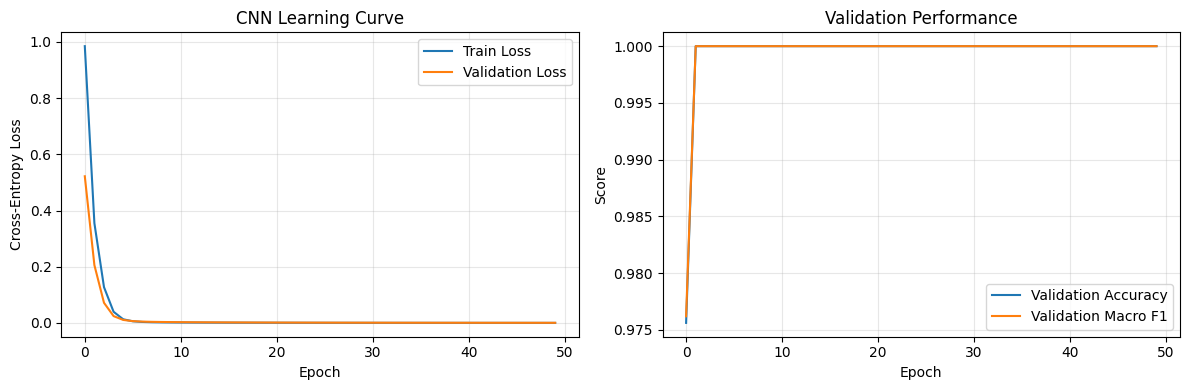

In [93]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Validation Loss")
axes[0].set_title("CNN Learning Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    history["val_accuracy"],
    label="Validation Accuracy"
)
axes[1].plot(
    history["val_macro_f1"],
    label="Validation Macro F1"
)
axes[1].set_title("Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Observation: the CNN learns the selected classes quickly

The CNN reaches a high validation score early. The fault-specific patterns observed above may help explain why the task is learnable, but this is an interpretation rather than proof that the CNN relies on those exact variables. Next, we evaluate on windows from the supplied test sequences.

In [94]:
# Step 9A: Prepare test windows for CNN

test_windows = []
test_window_labels = []

for label, filename in test_cases.items():
    data = load_tep_data(data_dir / filename)

    if label == 0:
        labels = np.zeros(len(data), dtype=int)
    else:
        labels = np.full(len(data), label, dtype=int)
        labels[:160] = 0

    # Use the scaler fitted on training portions only
    data_scaled = scaler.transform(data)

    # Create windows within each test sequence
    for start in range(
        0, len(data_scaled) - WINDOW_SIZE + 1, STRIDE
    ):
        end = start + WINDOW_SIZE

        # Assign the majority label within the window
        window_labels = labels[start:end]
        values, counts = np.unique(
            window_labels, return_counts=True
        )
        window_label = values[np.argmax(counts)]

        test_windows.append(data_scaled[start:end])
        test_window_labels.append(window_label)

X_cnn_test = np.array(test_windows, dtype=np.float32)
y_cnn_test = np.array(test_window_labels, dtype=int)

# Convert to PyTorch Conv1d input format
X_cnn_test_t = torch.tensor(
    X_cnn_test.transpose(0, 2, 1),
    dtype=torch.float32
)

y_cnn_test_idx = np.array(
    [label_to_index[y] for y in y_cnn_test]
)

print("CNN test windows:", X_cnn_test.shape)
print("CNN test tensor:", X_cnn_test_t.shape)
print("CNN test labels:", y_cnn_test.shape)

print("\nTest windows per class:")
for label in [0, 1, 2, 4]:
    print(label, np.sum(y_cnn_test == label))

CNN test windows: (732, 50, 52)
CNN test tensor: torch.Size([732, 52, 50])
CNN test labels: (732,)

Test windows per class:
0 267
1 155
2 155
4 155


### 6.6 Evaluate CNN predictions at the window level

Window-level metrics assess the classifier on each temporal segment. Because windows overlap, this score is not directly equivalent to a sample-level score or to an independent-run evaluation.

In [95]:
from sklearn.metrics import classification_report, confusion_matrix

cnn_model.eval()

with torch.no_grad():
    test_logits = cnn_model(X_cnn_test_t)
    test_pred_idx = test_logits.argmax(dim=1).cpu().numpy()

y_cnn_pred = np.array(
    [index_to_label[i] for i in test_pred_idx]
)

print(classification_report(
    y_cnn_test,
    y_cnn_pred,
    labels=[0, 1, 2, 4],
    target_names=["Normal", "Fault 1", "Fault 2", "Fault 4"],
    zero_division=0,
))

print("Confusion matrix:")
print(confusion_matrix(
    y_cnn_test,
    y_cnn_pred,
    labels=[0, 1, 2, 4]
))

              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99       267
     Fault 1       1.00      1.00      1.00       155
     Fault 2       1.00      0.98      0.99       155
     Fault 4       0.99      1.00      1.00       155

    accuracy                           0.99       732
   macro avg       1.00      0.99      0.99       732
weighted avg       0.99      0.99      0.99       732

Confusion matrix:
[[266   0   0   1]
 [  0 155   0   0]
 [  3   0 152   0]
 [  0   0   0 155]]


Looking at the confusion matrix:
- Normal: Classified 266/277 correctly.
- Fault 1: Classified all 155 correctly.
- Fault 2: Classified 152/155 correctly; 3 were misclassified as Normal.
- Fault 4: Classified all 155 correctly.

At the moment CNN misclassified some windows of Fault 2, and misclassified one Normal window as Fault 4.

Comparison of the models so far:

Model /	Evaluation / unit	/ Accuracy / Macro F1
- Logistic Regression	/ 개별 sample	/ 99.09%	/ 99.15%
- Random Forest	/ 개별 sample	/ 97.89%	/ 98.06%
- 1D CNN	/ 50-sample window	/ 99.45%	/ 99.45%

Although CNN has the highest numbers, because the standards are different, this table alone is not enough to conclude that CNN is the best. For fair comparisons, we need to use the same test sequence, the same evaluation standard, and the same label convention. For the next step, let's make the comparison fair.

### Window-level error analysis

The confusion matrix identifies which window classes are most often confused. To compare this model more directly with the classical sample-wise baselines, we next aggregate window predictions back to individual samples.

Step 10A — Store window and location data safely

In [96]:
from collections import defaultdict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
import numpy as np

# Map each test window back to its original test sequence and sample indices
window_predictions = np.array(
    [index_to_label[i] for i in test_pred_idx]
)

sample_votes = {}
sample_truth = {}

for label, filename in test_cases.items():
    data = load_tep_data(data_dir / filename)

    # TEP convention: first 160 test samples are normal
    true_labels = np.full(len(data), label, dtype=int)

    if label != 0:
        true_labels[:160] = 0

    sample_votes[filename] = defaultdict(list)
    sample_truth[filename] = true_labels

    scaled_data = scaler.transform(data)

    for start in range(
        0, len(scaled_data) - WINDOW_SIZE + 1, STRIDE
    ):
        end = start + WINDOW_SIZE

        # Find the corresponding window prediction
        # Each file's windows are stored consecutively in test_cases order.
        # We reconstruct predictions using a running index below.

## 7. Convert window predictions to sample-level predictions

Each sample can appear in multiple overlapping windows. We map each window prediction back to its original sample and combine the votes. This produces one prediction per sample, making the CNN's output more comparable with the Logistic Regression and Random Forest sample-level results.

In [97]:
test_windows = []
test_window_labels = []
test_window_meta = []

for label, filename in test_cases.items():
    data = load_tep_data(data_dir / filename)

    true_labels = np.full(len(data), label, dtype=int)

    if label != 0:
        true_labels[:160] = 0

    data_scaled = scaler.transform(data)

    for start in range(
        0, len(data_scaled) - WINDOW_SIZE + 1, STRIDE
    ):
        end = start + WINDOW_SIZE

        window_labels = true_labels[start:end]
        values, counts = np.unique(
            window_labels, return_counts=True
        )
        majority_label = values[np.argmax(counts)]

        test_windows.append(data_scaled[start:end])
        test_window_labels.append(majority_label)
        test_window_meta.append((filename, start, end))

X_cnn_test = np.asarray(test_windows, dtype=np.float32)
y_cnn_test = np.asarray(test_window_labels, dtype=int)

X_cnn_test_t = torch.tensor(
    X_cnn_test.transpose(0, 2, 1),
    dtype=torch.float32
)

cnn_model.eval()

with torch.no_grad():
    test_logits = cnn_model(X_cnn_test_t)
    test_pred_idx = test_logits.argmax(dim=1).cpu().numpy()

window_predictions = np.array(
    [index_to_label[i] for i in test_pred_idx]
)

print("Windows:", len(test_window_meta))
print("Predictions:", len(window_predictions))
print("Metadata examples:", test_window_meta[:3])

Windows: 732
Predictions: 732
Metadata examples: [('d00_te.dat', 0, 50), ('d00_te.dat', 5, 55), ('d00_te.dat', 10, 60)]


### 7.1 Aggregate window votes for each sample

The next cell performs majority voting using the saved window-to-sample metadata, then reports sample-level metrics and confusion matrix.

In [98]:
from collections import defaultdict
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# Collect CNN votes for each original sample
sample_votes = {
    filename: defaultdict(list)
    for filename in test_cases.values()
}

sample_truth = {}

for label, filename in test_cases.items():
    data = load_tep_data(data_dir / filename)

    true_labels = np.full(len(data), label, dtype=int)

    # First 160 samples of fault test sequences are normal
    if label != 0:
        true_labels[:160] = 0

    sample_truth[filename] = true_labels

# Map each window prediction back to its samples
for (filename, start, end), pred in zip(
    test_window_meta, window_predictions
):
    for sample_idx in range(start, end):
        sample_votes[filename][sample_idx].append(pred)

# Majority vote for each sample
y_true_sample = []
y_pred_sample = []

for filename in test_cases.values():
    true_labels = sample_truth[filename]

    for sample_idx in range(len(true_labels)):
        votes = sample_votes[filename].get(sample_idx, [])

        # Some edge samples may not belong to any window.
        # Skip those samples for this first comparison.
        if not votes:
            continue

        values, counts = np.unique(votes, return_counts=True)
        pred = values[np.argmax(counts)]

        y_true_sample.append(true_labels[sample_idx])
        y_pred_sample.append(pred)

y_true_sample = np.array(y_true_sample)
y_pred_sample = np.array(y_pred_sample)

print("Evaluated samples:", len(y_true_sample))
print(
    "Sample-level accuracy:",
    round(accuracy_score(y_true_sample, y_pred_sample), 4)
)
print(
    "Sample-level macro F1:",
    round(f1_score(
        y_true_sample,
        y_pred_sample,
        labels=[0, 1, 2, 4],
        average="macro",
        zero_division=0
    ), 4)
)

print("\nClassification report:")
print(classification_report(
    y_true_sample,
    y_pred_sample,
    labels=[0, 1, 2, 4],
    target_names=["Normal", "Fault 1", "Fault 2", "Fault 4"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    y_true_sample,
    y_pred_sample,
    labels=[0, 1, 2, 4]
))

Evaluated samples: 3840
Sample-level accuracy: 0.9935
Sample-level macro F1: 0.9939

Classification report:
              precision    recall  f1-score   support

      Normal       0.98      1.00      0.99      1440
     Fault 1       1.00      0.99      1.00       800
     Fault 2       1.00      0.97      0.99       800
     Fault 4       1.00      1.00      1.00       800

    accuracy                           0.99      3840
   macro avg       1.00      0.99      0.99      3840
weighted avg       0.99      0.99      0.99      3840

Confusion matrix:
[[1440    0    0    0]
 [   5  795    0    0]
 [  20    0  780    0]
 [   0    0    0  800]]


This time we converted CNN's window predictions into sample-level predictions, allowing the direct comparison with Logistic Regression results. It seems that although CNN does perform better than Logistic Regression, the difference is not that big.

Logistic Regression
99.09%
Accuracy

Random Forest
97.89%
Accuracy

1D CNN
99.35%
Accuracy

The accuracy of CNN is 0.26 percent points higher than that of Logistic Regression. Macro F1 is also 0.24 percent points higher.

Looking at the confusion matrix:
- CNN classified all Normal and Fault 4 samples correctly.
- 5 Fault 1 samples were misclassified as Normal.
- 20 Fault 2 samples were misclassified as Normal.

Hence, the major issue is misclassification of faulty samples as Normal. Let's take a look at how many samples from the fault onset the CNN takes for it to detect a fault.

### What does sample-level evaluation add?

Sample-level voting gives a more direct comparison with classical models, but it is not an independent new test: it aggregates predictions from the same test sequences. The comparison is useful for understanding the effect of temporal windows and voting, not for claiming an independent benchmark win.

In [99]:
# Step 11A: Detection delay and false alarm analysis

import numpy as np
import pandas as pd

SAMPLES_PER_FILE = 960
FAULT_ONSET = 160       # zero-based index; 161st sample
SUSTAINED_COUNT = 3

fault_results = []

for file_idx, (fault_label, filename) in enumerate(test_cases.items()):

    start_idx = file_idx * SAMPLES_PER_FILE
    end_idx = start_idx + SAMPLES_PER_FILE

    # Predictions and true labels for this sequence
    pred = y_pred_sample[start_idx:end_idx]
    true = sample_truth[filename]

    if fault_label == 0:
        continue  # Normal-only sequence has no fault onset

    # 1. False alarms before the fault starts
    pre_fault_pred = pred[:FAULT_ONSET]
    false_alarm_count = np.sum(pre_fault_pred != 0)

    # 2. Search for sustained correct fault predictions
    detection_idx = None

    for i in range(FAULT_ONSET, len(pred) - SUSTAINED_COUNT + 1):
        if np.all(
            pred[i:i + SUSTAINED_COUNT] == fault_label
        ):
            detection_idx = i
            break

    if detection_idx is None:
        delay = None
        detection_sample = None
    else:
        delay = detection_idx - FAULT_ONSET
        detection_sample = detection_idx + 1  # one-based sample number

    fault_results.append({
        "Fault": fault_label,
        "File": filename,
        "False alarms before onset": int(false_alarm_count),
        "First sustained detection (sample)": detection_sample,
        "Detection delay (samples)": delay,
        "Detected": detection_idx is not None,
    })

delay_df = pd.DataFrame(fault_results)
display(delay_df)

,Fault,File,False alarms before onset,First sustained detection (sample),Detection delay (samples),Detected
0,1,d01_te.dat,0,166,5,True
1,2,d02_te.dat,0,181,20,True
2,4,d04_te.dat,0,161,0,True


## 8. Detection delay around fault onset

Classification accuracy summarizes all samples, while detection delay asks a time-sensitive question: how soon after the known onset does the model produce a sustained correct fault prediction? We require three consecutive correct predictions to reduce sensitivity to a single lucky prediction.

The reported delay is measured in **samples**, not seconds, unless the sampling interval is explicitly established.

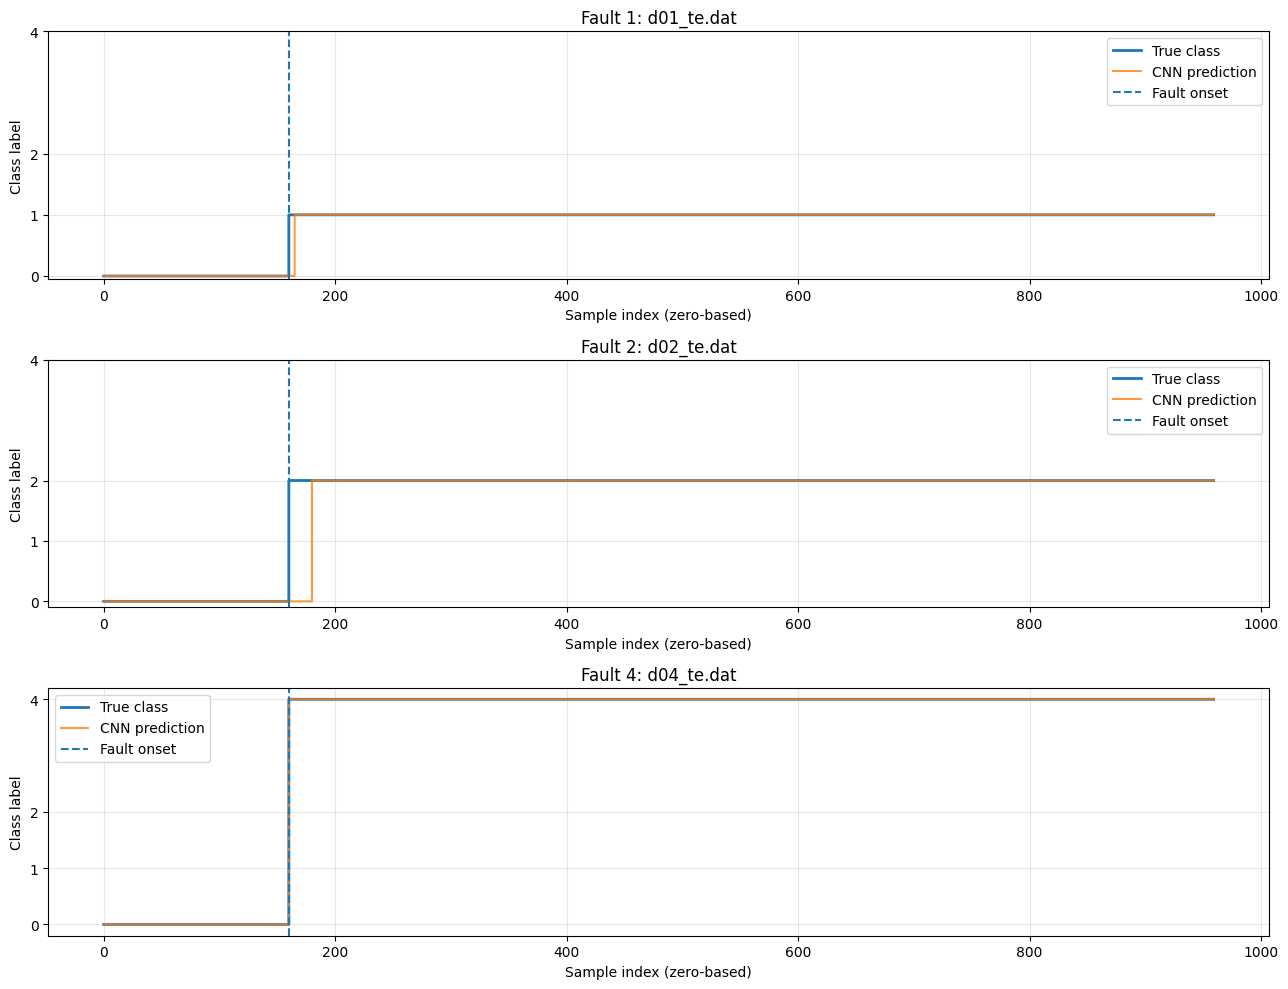

In [100]:
# Step 11B: Plot predictions around fault onset

import matplotlib.pyplot as plt

fault_cases = [
    (1, "d01_te.dat"),
    (2, "d02_te.dat"),
    (4, "d04_te.dat"),
]

fig, axes = plt.subplots(3, 1, figsize=(13, 10))

for ax, (fault_label, filename) in zip(axes, fault_cases):

    file_idx = list(test_cases.values()).index(filename)
    start_idx = file_idx * SAMPLES_PER_FILE
    end_idx = start_idx + SAMPLES_PER_FILE

    pred = y_pred_sample[start_idx:end_idx]
    true = sample_truth[filename]

    samples = np.arange(len(pred))

    ax.step(samples, true, where="post",
            label="True class", linewidth=2)
    ax.step(samples, pred, where="post",
            label="CNN prediction", alpha=0.8)

    ax.axvline(
        FAULT_ONSET,
        linestyle="--",
        label="Fault onset"
    )

    ax.set_title(f"Fault {fault_label}: {filename}")
    ax.set_xlabel("Sample index (zero-based)")
    ax.set_ylabel("Class label")
    ax.set_yticks([0, 1, 2, 4])
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### 8.1 Relate onset behavior to process-variable trajectories

To interpret the detection-delay results, inspect selected variables around the documented onset. This is a targeted diagnostic view: it connects model behavior with process changes without repeating the full time-series analysis from the previous section.

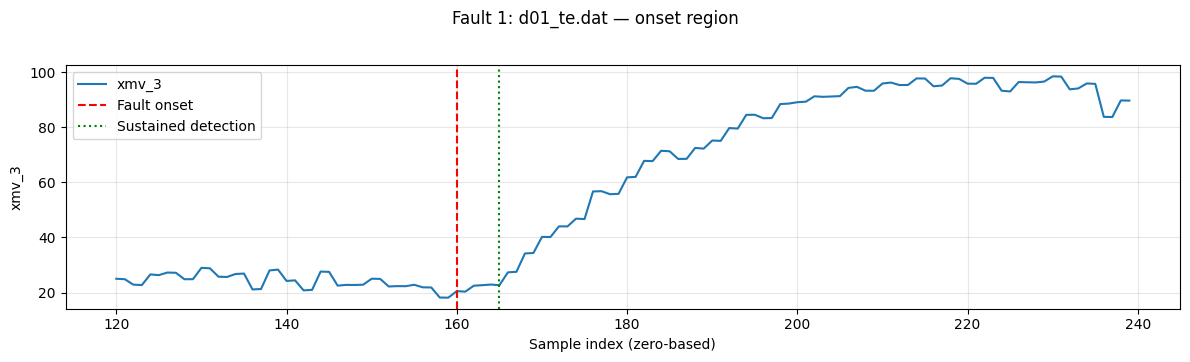

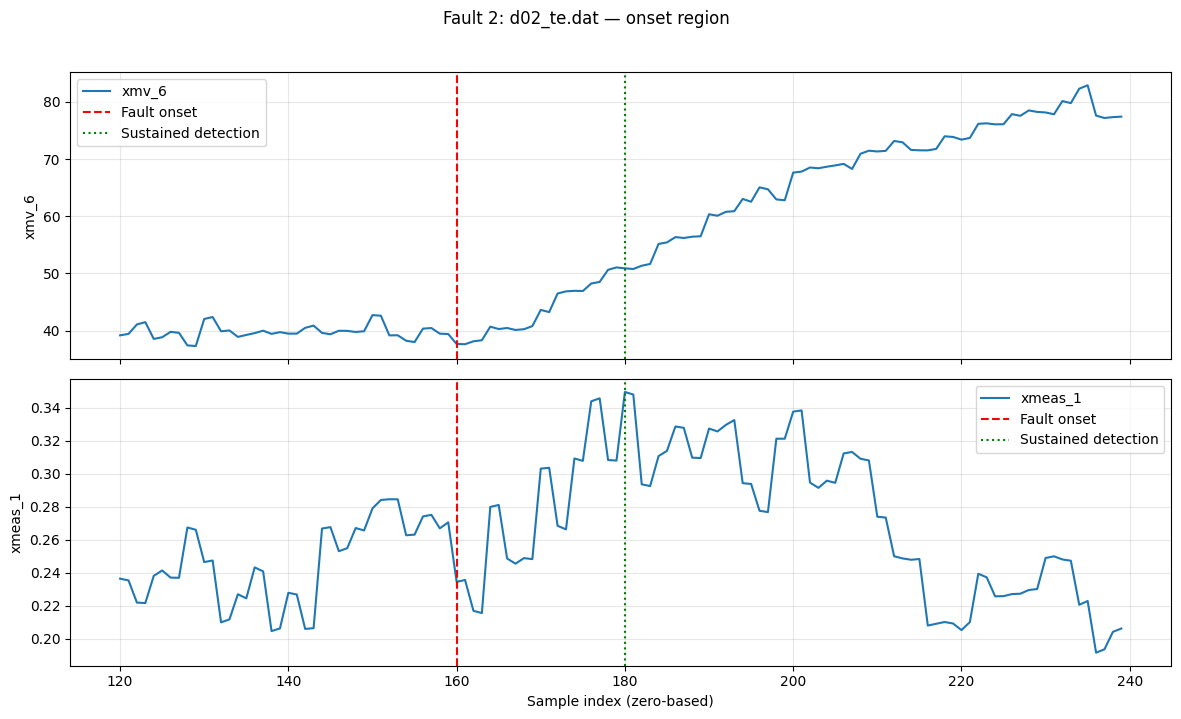

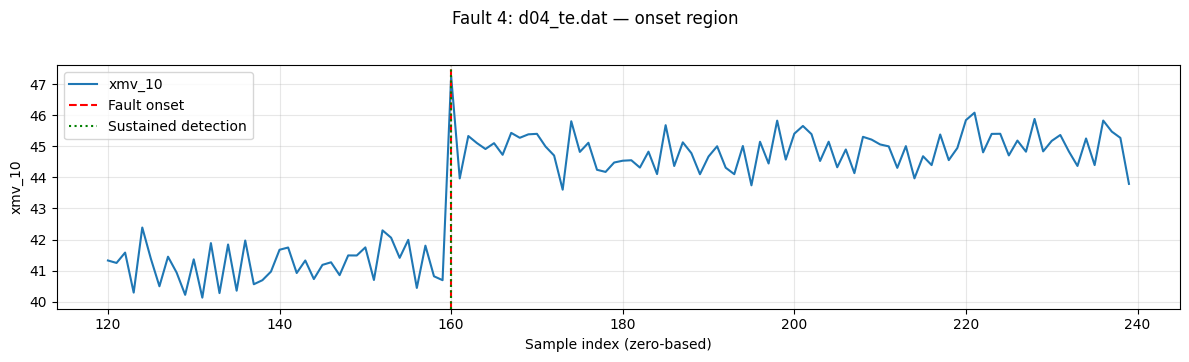

In [101]:
import numpy as np
import matplotlib.pyplot as plt

# X_test column order:
# xmeas_1 ... xmeas_41, xmv_1 ... xmv_11
feature_names = (
    [f"xmeas_{i}" for i in range(1, 42)]
    + [f"xmv_{i}" for i in range(1, 12)]
)

# Variables to inspect for each fault
fault_variables = {
    1: ["xmv_3"],
    2: ["xmv_6", "xmeas_1"],
    4: ["xmv_10"],
}

FAULT_ONSET = 160
PLOT_START = 120
PLOT_END = 240
SAMPLES_PER_FILE = 960

# Prediction-based sustained detection samples (zero-based)
detection_indices = {
    1: 165,  # sample 166, delay 5
    2: 180,  # sample 181, delay 20
    4: 160,  # sample 161, delay 0
}

for file_idx, (fault_label, filename) in enumerate(test_cases.items()):
    if fault_label == 0:
        continue

    # Select the corresponding test sequence
    start = file_idx * SAMPLES_PER_FILE
    X_file = X_test[start:start + SAMPLES_PER_FILE]

    # Safety check
    assert X_file.shape[0] == SAMPLES_PER_FILE

    fig, axes = plt.subplots(
        len(fault_variables[fault_label]), 1,
        figsize=(12, 3.5 * len(fault_variables[fault_label])),
        sharex=True
    )

    axes = np.atleast_1d(axes)

    for ax, variable in zip(
        axes, fault_variables[fault_label]
    ):
        col_idx = feature_names.index(variable)
        values = X_file[:, col_idx]

        ax.plot(
            np.arange(PLOT_START, PLOT_END),
            values[PLOT_START:PLOT_END],
            label=variable
        )

        ax.axvline(
            FAULT_ONSET,
            color="red",
            linestyle="--",
            label="Fault onset"
        )

        ax.axvline(
            detection_indices[fault_label],
            color="green",
            linestyle=":",
            label="Sustained detection"
        )

        ax.set_ylabel(variable)
        ax.grid(True, alpha=0.3)
        ax.legend()

    axes[-1].set_xlabel("Sample index (zero-based)")
    fig.suptitle(
        f"Fault {fault_label}: {filename} — onset region",
        y=1.02
    )
    plt.tight_layout()
    plt.show()

### 8.2 Fault-specific onset patterns summary

Potential reasons for detection delay for Fault 2:
- xmv_6 gradually increases from 38-40 near the fault onset (index 160) to 51 around index 180. The change is not abrupt but gradual.
- xmeas_10 fluctuates all over the place without any specific pattern. At the fault onset, it shows some decrease, before its sudden increase again soon, which is followed by another major decrease.

### 8.3 Inspect the Fault 2 onset errors

The following diagnostic focuses on the samples immediately after Fault 2 begins. It is intended to localize the model's errors in time. It does not establish why the process behaves this way; that requires separate process knowledge or experiments.

In [102]:
# Fault 2: d02_te.dat
fault2_start = 2 * 960

pred = y_pred_sample[fault2_start:fault2_start + 960]
true = sample_truth["d02_te.dat"]

onset = 160
end = 196

# Print only samples around fault onset
print("Sample | True | Predicted | Correct")
for i in range(150, end):
    print(
        f"{i:6d} | {true[i]:4d} | {pred[i]:9d} | "
        f"{true[i] == pred[i]}"
    )

# First sample correctly classified as Fault 2 after onset
correct_fault_indices = np.where(
    (np.arange(onset, 960) >= onset) &
    (true[onset:] == 2) &
    (pred[onset:] == 2)
)[0] + onset

if len(correct_fault_indices):
    print("\nFirst correct Fault 2 prediction:", correct_fault_indices[0])

# First sustained detection: 3 consecutive Fault 2 predictions
first_sustained = None

for i in range(onset, 960 - 2):
    if np.all(pred[i:i+3] == 2):
        first_sustained = i
        break

print("First sustained detection index:", first_sustained)

Sample | True | Predicted | Correct
   150 |    0 |         0 | True
   151 |    0 |         0 | True
   152 |    0 |         0 | True
   153 |    0 |         0 | True
   154 |    0 |         0 | True
   155 |    0 |         0 | True
   156 |    0 |         0 | True
   157 |    0 |         0 | True
   158 |    0 |         0 | True
   159 |    0 |         0 | True
   160 |    2 |         0 | False
   161 |    2 |         0 | False
   162 |    2 |         0 | False
   163 |    2 |         0 | False
   164 |    2 |         0 | False
   165 |    2 |         0 | False
   166 |    2 |         0 | False
   167 |    2 |         0 | False
   168 |    2 |         0 | False
   169 |    2 |         0 | False
   170 |    2 |         0 | False
   171 |    2 |         0 | False
   172 |    2 |         0 | False
   173 |    2 |         0 | False
   174 |    2 |         0 | False
   175 |    2 |         0 | False
   176 |    2 |         0 | False
   177 |    2 |         0 | False
   178 |    2 |       

### Interpretation

The analysis indicates that some CNN predictions near Fault 2 onset are initially Normal before the model settles on the correct fault label. This is consistent with a gradual transition in the observed variables. Keep the distinction between the first correct prediction and the sustained detection rule: the reported delay depends on the rule defined earlier.

In [103]:
fault_files = {
    1: "d01_te.dat",
    2: "d02_te.dat",
    4: "d04_te.dat",
}

for fault_label, filename in fault_files.items():
    file_idx = list(test_cases.values()).index(filename)
    start = file_idx * 960

    pred = y_pred_sample[start:start + 960]
    true = sample_truth[filename]

    onset = 160

    # First correct prediction after onset
    correct_idx = np.where(
        (true[onset:] == fault_label) &
        (pred[onset:] == fault_label)
    )[0]

    first_correct = (
        int(correct_idx[0] + onset)
        if len(correct_idx) else None
    )

    # First sustained detection: 3 consecutive fault predictions
    sustained_idx = None

    for i in range(onset, 960 - 2):
        if np.all(pred[i:i+3] == fault_label):
            sustained_idx = i
            break

    # Count incorrectly classified samples before sustained detection
    stop = sustained_idx if sustained_idx is not None else 960
    wrong_before_detection = int(
        np.sum(pred[onset:stop] != fault_label)
    )

    print(f"\nFault {fault_label}: {filename}")
    print("First correct prediction:", first_correct)
    print("Sustained detection index:", sustained_idx)
    print(
        "Wrong predictions before sustained detection:",
        wrong_before_detection
    )


Fault 1: d01_te.dat
First correct prediction: 165
Sustained detection index: 165
Wrong predictions before sustained detection: 5

Fault 2: d02_te.dat
First correct prediction: 180
Sustained detection index: 180
Wrong predictions before sustained detection: 20

Fault 4: d04_te.dat
First correct prediction: 160
Sustained detection index: 160
Wrong predictions before sustained detection: 0


## Milestone 4 — Process interpretation

The previous sections establish predictive performance and identify candidate variables. This milestone asks a different question: **are the observed model signals consistent with interpretable, fault-specific changes in the process data?**

We combine selected time-series patterns, class-wise distributions, standardized mean differences, and Random Forest importance. These are complementary descriptive and predictive views, not independent experiments and not proof of causality.

## Milestone 4 — Process Interpretation

### 4.1 Quantify fault signatures

We summarize how selected variables differ between Normal and each fault. The selected features come from the earlier model-importance and time-series analyses, so this section interprets prior findings rather than introducing a new feature-selection procedure.

In [104]:
# Check the shape of the test dataset
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

# Define the 52 process variable names
feature_names = (
    [f"xmeas_{i}" for i in range(1, 42)]
    + [f"xmv_{i}" for i in range(1, 12)]
)

print("Number of features:", len(feature_names))
print("First 5 features:", feature_names[:5])
print("Last 5 features:", feature_names[-5:])

# Check the class labels
import numpy as np

print("Unique labels:", np.unique(y_test))

X_test shape: (3840, 52)
y_test shape: (3840,)
Number of features: 52
First 5 features: ['xmeas_1', 'xmeas_2', 'xmeas_3', 'xmeas_4', 'xmeas_5']
Last 5 features: ['xmv_7', 'xmv_8', 'xmv_9', 'xmv_10', 'xmv_11']
Unique labels: [0 1 2 4]


In [105]:
import pandas as pd
import numpy as np

# Create a DataFrame from the test data
df_test = pd.DataFrame(X_test, columns=feature_names)
df_test["label"] = y_test

# Map labels to readable class names
label_names = {
    0: "Normal",
    1: "Fault 1",
    2: "Fault 2",
    4: "Fault 4"
}

df_test["class_name"] = df_test["label"].map(label_names)

# Calculate mean and standard deviation for each class
class_stats = df_test.groupby("class_name")[feature_names].agg(
    ["mean", "std"]
)

# Display statistics for selected features
selected_features = [
    "xmeas_1",
    "xmeas_10",
    "xmeas_18",
    "xmeas_34",
    "xmeas_4",
    "xmv_10",
    "xmv_3",
    "xmv_6"
]

display(class_stats[selected_features].round(3))

xmeas_1        xmeas_10        xmeas_18        xmeas_34         \
              mean    std     mean    std     mean    std     mean    std   
class_name                                                                  
Fault 1      0.760  0.096    0.318  0.020   68.069  1.486    2.314  0.054   
Fault 2      0.283  0.035    0.685  0.069   63.265  1.056    1.514  0.255   
Fault 4      0.250  0.029    0.337  0.013   65.731  0.387    2.260  0.026   
Normal       0.250  0.029    0.337  0.012   65.850  0.396    2.265  0.025   

           xmeas_4         xmv_10          xmv_3          xmv_6         
              mean    std    mean    std    mean    std    mean    std  
class_name                                                              
Fault 1      8.799  0.210  41.008  0.705  74.758  9.451  37.807  2.481  
Fault 2      9.612  0.099  41.464  0.546  27.817  3.409  81.510  8.282  
Fault 4      9.351  0.080  44.892  0.512  24.576  2.894  40.104  1.550  
Normal       9.347  0.078  41.108  0.550  24.615  2.892  40.018  1.478

### 4.2 Visualize the selected fault signatures

The following plots show the variables selected for each fault: `xmeas_1` and `xmv_3` for Fault 1, `xmeas_10` and `xmv_6` for Fault 2, and `xmv_10` for Fault 4. These plots complement the class-wise statistics by showing how the signal evolves over time.

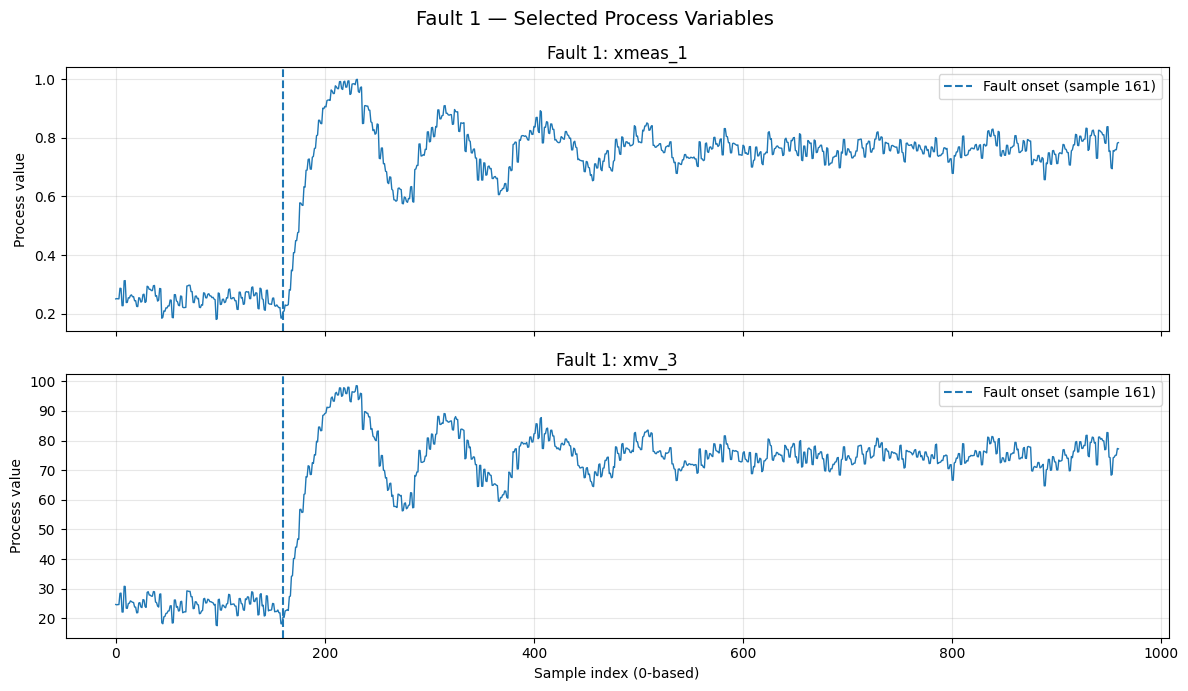

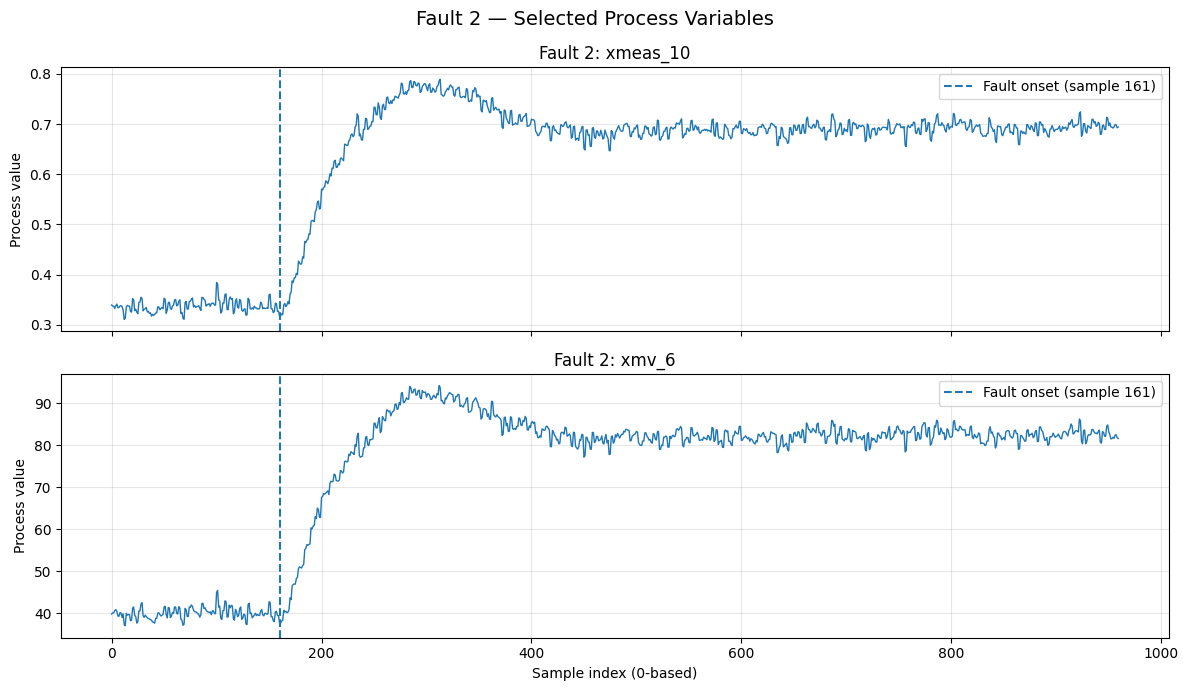

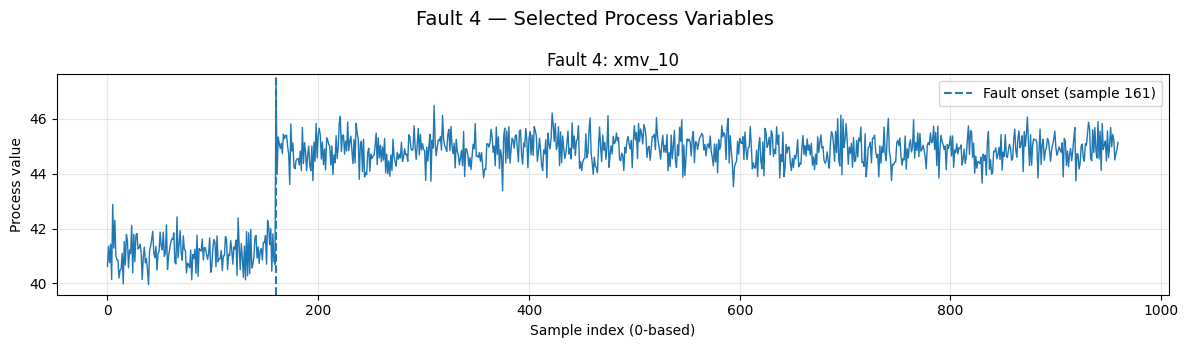

In [106]:
import matplotlib.pyplot as plt
import numpy as np

# Variables selected for each fault
fault_features = {
    1: ["xmeas_1", "xmv_3"],
    2: ["xmeas_10", "xmv_6"],
    4: ["xmv_10"]
}

# Each file contains 960 samples.
# Fault starts at index 160 (sample 161).
fault_onset = 160

for fault_id, features in fault_features.items():
    filename = test_cases[fault_id]

    # Load the test sequence using your existing loader
    X_seq = load_tep_data(
        f"/content/tep_data/{filename}",
        expected_variables=52
    )

    time = np.arange(len(X_seq))

    fig, axes = plt.subplots(
        len(features), 1,
        figsize=(12, 3.5 * len(features)),
        sharex=True
    )

    # Make axes iterable even when there is only one feature
    axes = np.atleast_1d(axes)

    for ax, feature in zip(axes, features):
        feature_idx = feature_names.index(feature)

        ax.plot(time, X_seq[:, feature_idx], linewidth=1)
        ax.axvline(
            fault_onset,
            linestyle="--",
            label="Fault onset (sample 161)"
        )

        ax.set_title(f"Fault {fault_id}: {feature}")
        ax.set_ylabel("Process value")
        ax.grid(alpha=0.3)
        ax.legend()

    axes[-1].set_xlabel("Sample index (0-based)")
    fig.suptitle(
        f"Fault {fault_id} — Selected Process Variables",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()

### Qualitative summary of the observed signatures

Use the table below as a concise record of the patterns visible in the selected sequences. Statements such as “rise,” “spike,” or “settling” describe the plotted data; they should not be interpreted as a causal process diagnosis without domain evidence.

In [107]:
# Calculate mean differences relative to Normal
mean_stats = df_test.groupby("class_name")[feature_names].mean()

selected_features = [
    "xmeas_1",
    "xmv_3",
    "xmeas_10",
    "xmv_6",
    "xmv_10"
]

fault_signature = pd.DataFrame(index=selected_features)

fault_signature["Normal mean"] = mean_stats.loc[
    "Normal", selected_features
]

for fault in ["Fault 1", "Fault 2", "Fault 4"]:
    fault_signature[f"{fault} mean"] = mean_stats.loc[
        fault, selected_features
    ]
    fault_signature[f"{fault} difference"] = (
        mean_stats.loc[fault, selected_features]
        - mean_stats.loc["Normal", selected_features]
    )

display(fault_signature.round(3))

,Normal mean,Fault 1 mean,Fault 1 difference,Fault 2 mean,Fault 2 difference,Fault 4 mean,Fault 4 difference
xmeas_1,0.250,0.760,0.510,0.283,0.032,0.250,-0.000
xmv_3,24.615,74.758,50.143,27.817,3.202,24.576,-0.040
xmeas_10,0.337,0.318,-0.019,0.685,0.348,0.337,0.000
xmv_6,40.018,37.807,-2.211,81.510,41.492,40.104,0.087
xmv_10,41.108,41.008,-0.100,41.464,0.356,44.892,3.784


### 4.2 Standardize mean differences before comparing effect sizes

Raw mean differences are not comparable across variables with different units and scales. Standardized mean difference (SMD) expresses the difference between class means relative to pooled variability. A large absolute SMD indicates strong separation in these observed data, but does not establish causal importance or out-of-sample predictive value.

In [108]:
import numpy as np
import pandas as pd

selected_features = [
    "xmeas_1",
    "xmv_3",
    "xmeas_10",
    "xmv_6",
    "xmv_10"
]

# Calculate class-wise mean and standard deviation separately
class_mean = df_test.groupby("class_name")[selected_features].mean()
class_std = df_test.groupby("class_name")[selected_features].std()

normal_mean = class_mean.loc["Normal"]
normal_std = class_std.loc["Normal"]

smd_results = {}

for fault in ["Fault 1", "Fault 2", "Fault 4"]:
    fault_mean = class_mean.loc[fault]
    fault_std = class_std.loc[fault]

    pooled_std = np.sqrt(
        (fault_std**2 + normal_std**2) / 2
    )

    smd_results[fault] = (
        (fault_mean - normal_mean) / pooled_std
    )

smd_table = pd.DataFrame(smd_results)
smd_table.index.name = "Feature"

display(smd_table.round(3))

,Fault 1,Fault 2,Fault 4
Feature,,,
xmeas_1,7.184,1.013,-0.013
xmv_3,7.175,1.013,-0.014
xmeas_10,-1.134,6.986,0.040
xmv_6,-1.083,6.975,0.057
xmv_10,-0.158,0.649,7.122


### 4.3 Synthesize statistical separation and model importance

The comparison below places Random Forest importance beside fault-specific SMD values. The two measures answer different questions: importance reflects how the fitted model uses a feature, while SMD describes how strongly that feature differs between two observed classes.

In [109]:
# Compare RF feature importance with fault-specific SMD

# Use the Random Forest model already fitted in your notebook.
# If your model variable has a different name, replace rf_model.
rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names,
    name="RF importance"
).sort_values(ascending=False)

# Show the most important RF features
display(rf_importance.head(15).to_frame().round(4))

# Compare importance for the selected fault signatures
signature_features = [
    "xmeas_1",
    "xmv_3",
    "xmeas_10",
    "xmv_6",
    "xmv_10"
]

comparison = pd.DataFrame({
    "RF importance": rf_importance.loc[signature_features],
    "Fault 1 SMD": smd_table["Fault 1"],
    "Fault 2 SMD": smd_table["Fault 2"],
    "Fault 4 SMD": smd_table["Fault 4"]
})

display(comparison.round(3))

,RF importance
xmv_10,0.2557
xmeas_1,0.0716
xmv_6,0.0699
xmv_3,0.0649
xmeas_18,0.0582
xmeas_10,0.0505
xmeas_34,0.0496
xmeas_4,0.0481
xmeas_28,0.0442
xmv_9,0.0365


,RF importance,Fault 1 SMD,Fault 2 SMD,Fault 4 SMD
xmeas_1,0.072,7.184,1.013,-0.013
xmv_3,0.065,7.175,1.013,-0.014
xmeas_10,0.050,-1.134,6.986,0.040
xmv_6,0.070,-1.083,6.975,0.057
xmv_10,0.256,-0.158,0.649,7.122


### Milestone 4 conclusion

Across the selected analyses, different faults show different candidate signatures. This improves interpretability, but these signals remain associations in the available data. We now return to the practical question: where do the models fail, and can a temporal architecture improve the error pattern?

# Milestone 5 — Error Analysis and Advanced Temporal Models

## Research question

The CNN has strong results, but overall accuracy alone does not reveal where it fails. We first localize errors by class and time, then compare a GRU with the CNN under the same windowing and evaluation setup.

## 9. Examine the errors before adding another model

A new architecture is only useful if it addresses a meaningful limitation or provides a fair comparison. We inspect class-wise errors and focus on Normal/Fault 2 confusion and errors near fault onset, which were visible in the classical and CNN results.

In [110]:
# Inspect prediction variables already available in the notebook

candidate_vars = [
    "y_test",
    "y_true_sample",
    "y_pred_sample",
    "window_predictions",
    "sample_truth",
    "test_window_meta"
]

for var_name in candidate_vars:
    exists = var_name in globals()
    print(f"{var_name}: {'available' if exists else 'not found'}")

# Check shapes of sample-level predictions
if "y_true_sample" in globals():
    print("CNN sample-level truth:", np.shape(y_true_sample))

if "y_pred_sample" in globals():
    print("CNN sample-level predictions:", np.shape(y_pred_sample))

y_test: available
y_true_sample: available
y_pred_sample: available
window_predictions: available
sample_truth: available
test_window_meta: available
CNN sample-level truth: (3840,)
CNN sample-level predictions: (3840,)


### 9.1 Compare error patterns across models

The next cells consolidate confusion matrices and class-wise error counts. CNN and classical models do not have identical prediction mechanisms: the CNN uses overlapping windows and majority voting, while Logistic Regression and Random Forest classify individual samples. Interpret differences with that distinction in mind.

In [111]:
for name, model in models.items():
    print(f"{name}: fitted = {hasattr(model, 'classes_')}")

    if hasattr(model, "named_steps"):
        classifier = model.named_steps["classifier"]
        print(f"  Classifier fitted = {hasattr(classifier, 'classes_')}")

Logistic Regression: fitted = True
  Classifier fitted = True
Random Forest: fitted = True


In [112]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import pandas as pd

y_true = np.asarray(y_test)

y_pred_lr = models["Logistic Regression"].predict(X_test)
y_pred_rf = models["Random Forest"].predict(X_test)
y_pred_cnn = np.asarray(y_pred_sample)

model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "CNN + majority voting": y_pred_cnn
}

results = []

for name, pred in model_predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Macro F1": f1_score(
            y_true, pred,
            labels=[0, 1, 2, 4],
            average="macro"
        ),
        "Number of errors": int(np.sum(y_true != pred))
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Macro F1,Number of errors
0,Logistic Regression,0.9909,0.9915,35
1,Random Forest,0.9789,0.9806,81
2,CNN + majority voting,0.9935,0.9939,25


### 9.2 Class-wise error analysis

Use confusion matrices and class-wise metrics to identify the dominant failure modes. This is more informative than comparing accuracy alone because different models can make different types of mistakes.

In [113]:
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd
import numpy as np

labels = [0, 1, 2, 4]
class_names = ["Normal", "Fault 1", "Fault 2", "Fault 4"]

# 1. Confusion matrix for each model
for model_name, predictions in model_predictions.items():
    print(f"\n{'=' * 20} {model_name} {'=' * 20}")

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=labels
    )

    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual {name}" for name in class_names],
        columns=[f"Pred {name}" for name in class_names]
    )

    display(cm_df)

    print("\nClassification report:")
    print(
        classification_report(
            y_true,
            predictions,
            labels=labels,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )


==================== Logistic Regression ====================


,Pred Normal,Pred Fault 1,Pred Fault 2,Pred Fault 4
Actual Normal,1425,1,14,0
Actual Fault 1,4,796,0,0
Actual Fault 2,16,0,784,0
Actual Fault 4,0,0,0,800



Classification report:
              precision    recall  f1-score   support

      Normal     0.9862    0.9896    0.9879      1440
     Fault 1     0.9987    0.9950    0.9969       800
     Fault 2     0.9825    0.9800    0.9812       800
     Fault 4     1.0000    1.0000    1.0000       800

    accuracy                         0.9909      3840
   macro avg     0.9918    0.9911    0.9915      3840
weighted avg     0.9909    0.9909    0.9909      3840


==================== Random Forest ====================


,Pred Normal,Pred Fault 1,Pred Fault 2,Pred Fault 4
Actual Normal,1373,0,67,0
Actual Fault 1,2,798,0,0
Actual Fault 2,12,0,788,0
Actual Fault 4,0,0,0,800



Classification report:
              precision    recall  f1-score   support

      Normal     0.9899    0.9535    0.9713      1440
     Fault 1     1.0000    0.9975    0.9987       800
     Fault 2     0.9216    0.9850    0.9523       800
     Fault 4     1.0000    1.0000    1.0000       800

    accuracy                         0.9789      3840
   macro avg     0.9779    0.9840    0.9806      3840
weighted avg     0.9799    0.9789    0.9791      3840


==================== CNN + majority voting ====================


,Pred Normal,Pred Fault 1,Pred Fault 2,Pred Fault 4
Actual Normal,1440,0,0,0
Actual Fault 1,5,795,0,0
Actual Fault 2,20,0,780,0
Actual Fault 4,0,0,0,800



Classification report:
              precision    recall  f1-score   support

      Normal     0.9829    1.0000    0.9914      1440
     Fault 1     1.0000    0.9938    0.9969       800
     Fault 2     1.0000    0.9750    0.9873       800
     Fault 4     1.0000    1.0000    1.0000       800

    accuracy                         0.9935      3840
   macro avg     0.9957    0.9922    0.9939      3840
weighted avg     0.9936    0.9935    0.9935      3840



### Interpretation of the class-wise errors

The key question is not simply which model has the highest score, but which classes are confused and in which direction. Random Forest's Normal-to-Fault-2 errors and the remaining Fault-2 errors deserve closer inspection. These patterns motivate the next targeted analysis.

In [114]:
import numpy as np
import pandas as pd

# Prediction arrays from the previous analysis
predictions = {
    "Logistic Regression": np.asarray(y_pred_lr),
    "Random Forest": np.asarray(y_pred_rf),
    "CNN + majority voting": np.asarray(y_pred_cnn),
}

# Test sequence order used when building X_test and y_test
test_file_order = list(test_cases.values())

fault_onset = 160  # zero-based index; sample 161 in 1-based notation
samples_per_file = 960

rows = []

for model_name, y_pred in predictions.items():
    for file_idx, filename in enumerate(test_file_order):
        start = file_idx * samples_per_file
        end = start + samples_per_file

        y_true_file = y_true[start:end]
        y_pred_file = y_pred[start:end]

        # Only fault sequences have a fault onset at index 160.
        # d00_te.dat is the normal sequence.
        if filename == "d00_te.dat":
            regions = {
                "Normal sequence": np.arange(0, samples_per_file)
            }
        else:
            regions = {
                "Before onset": np.arange(0, fault_onset),
                "After onset": np.arange(fault_onset, samples_per_file)
            }

        for region_name, local_indices in regions.items():
            errors = np.sum(
                y_true_file[local_indices] != y_pred_file[local_indices]
            )

            rows.append({
                "Model": model_name,
                "Sequence": filename,
                "Region": region_name,
                "Samples": len(local_indices),
                "Errors": int(errors),
                "Error rate": errors / len(local_indices)
            })

temporal_error_table = pd.DataFrame(rows)

display(
    temporal_error_table.style.format({
        "Error rate": "{:.2%}"
    })
)

,Model,Sequence,Region,Samples,Errors,Error rate
0,Logistic Regression,d00_te.dat,Normal sequence,960,13,1.35%
1,Logistic Regression,d01_te.dat,Before onset,160,1,0.62%
2,Logistic Regression,d01_te.dat,After onset,800,4,0.50%
3,Logistic Regression,d02_te.dat,Before onset,160,0,0.00%
4,Logistic Regression,d02_te.dat,After onset,800,16,2.00%
5,Logistic Regression,d04_te.dat,Before onset,160,1,0.62%
6,Logistic Regression,d04_te.dat,After onset,800,0,0.00%
7,Random Forest,d00_te.dat,Normal sequence,960,66,6.88%
8,Random Forest,d01_te.dat,Before onset,160,0,0.00%
9,Random Forest,d01_te.dat,After onset,800,2,0.25%


### 9.3 Localize Fault 2 errors in time

We examine where the Fault 2 errors occur relative to the documented onset. If errors cluster near the transition, that is consistent with a gradual process response making early samples harder to classify. It is not, by itself, proof of the underlying physical cause.

In [115]:
import numpy as np
import pandas as pd

fault2_file_index = test_file_order.index("d02_te.dat")
start = fault2_file_index * samples_per_file

y_true_fault2 = y_true[start:start + samples_per_file]

predictions = {
    "Logistic Regression": np.asarray(y_pred_lr),
    "Random Forest": np.asarray(y_pred_rf),
    "CNN + majority voting": np.asarray(y_pred_cnn),
}

rows = []

# Fault onset is at zero-based index 160
for model_name, y_pred in predictions.items():
    y_pred_fault2 = y_pred[start:start + samples_per_file]

    for left in range(160, 960, 100):
        right = min(left + 100, 960)

        true_segment = y_true_fault2[left:right]
        pred_segment = y_pred_fault2[left:right]

        errors = int(np.sum(true_segment != pred_segment))

        rows.append({
            "Model": model_name,
            "Sample range (0-based)": f"{left}-{right - 1}",
            "Samples": right - left,
            "Errors": errors,
            "Error rate (%)": 100 * errors / (right - left)
        })

fault2_error_timeline = pd.DataFrame(rows)

display(
    fault2_error_timeline.pivot(
        index="Sample range (0-based)",
        columns="Model",
        values="Error rate (%)"
    ).round(2)
)

Model,CNN + majority voting,Logistic Regression,Random Forest
Sample range (0-based),,,
160-259,20.0,16.0,12.0
260-359,0.0,0.0,0.0
360-459,0.0,0.0,0.0
460-559,0.0,0.0,0.0
560-659,0.0,0.0,0.0
660-759,0.0,0.0,0.0
760-859,0.0,0.0,0.0
860-959,0.0,0.0,0.0


### What the temporal error pattern suggests

If the mistakes concentrate soon after onset, that connects the error analysis to the earlier `xmeas_10` and `xmv_6` trajectories. The interpretation remains a hypothesis: the plots and error locations show temporal association, not a confirmed mechanism.

The onset behavior has already been visualized in the earlier detection-delay section. Rather than repeat the same plot, we move to a complementary experiment: compare the CNN with a GRU, another model designed to process sequential inputs.

### 9.4 GRU comparison: motivation

A GRU is a recurrent neural network that updates a hidden state as it reads a sequence. The comparison asks whether this alternative way of modeling temporal dependencies improves classification or detection delay relative to the CNN. We keep the window definitions and evaluation sets consistent for a more interpretable comparison.

In [116]:

# Check the existing window data before building the GRU

print("Training windows:", X_cnn_train.shape)
print("Validation windows:", X_cnn_val.shape)

print("Training labels:", y_cnn_train.shape)
print("Validation labels:", y_cnn_val.shape)

print("Unique training labels:", np.unique(y_cnn_train))
print("Unique validation labels:", np.unique(y_cnn_val))


Training windows: (272, 50, 52)
Validation windows: (41, 50, 52)
Training labels: (272,)
Validation labels: (41,)
Unique training labels: [0 1 2 4]
Unique validation labels: [0 1 2 4]


### 9.5 Define the GRU architecture

The GRU reads each 50-sample window and uses its final hidden state to classify the window into one of the four classes.

In [117]:

import torch
import torch.nn as nn

class GRUClassifier(nn.Module):
    def __init__(
        self,
        input_dim=52,
        hidden_dim=32,
        num_layers=1,
        num_classes=4
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # x: (batch_size, sequence_length, input_dim)
        _, hidden = self.gru(x)

        # hidden: (num_layers, batch_size, hidden_dim)
        last_hidden = hidden[-1]

        # logits: (batch_size, num_classes)
        out = self.fc(last_hidden)

        return out


In [118]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

gru_model = GRUClassifier(
    input_dim=52,
    hidden_dim=32,
    num_layers=1,
    num_classes=4
).to(device)

dummy_input = torch.randn(8, 50, 52).to(device)

with torch.no_grad():
    dummy_output = gru_model(dummy_input)

print("Device:", device)
print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in gru_model.parameters()
        if p.requires_grad)
)


Device: cpu
Input shape: torch.Size([8, 50, 52])
Output shape: torch.Size([8, 4])
Trainable parameters: 8388


### 9.6 Prepare GRU training data

The existing CNN windows are reused so the architecture comparison is not confounded by different window construction. Labels are mapped to consecutive class indices for PyTorch's cross-entropy loss, while original labels are retained for reporting.

In [119]:

import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Convert original labels: 0, 1, 2, 4 -> 0, 1, 2, 3
label_to_index = {0: 0, 1: 1, 2: 2, 4: 3}

y_train_encoded = np.array([
    label_to_index[int(label)] for label in y_cnn_train
])

y_val_encoded = np.array([
    label_to_index[int(label)] for label in y_cnn_val
])

# Convert arrays to PyTorch tensors
X_train_tensor = torch.tensor(
    X_cnn_train, dtype=torch.float32
)
y_train_tensor = torch.tensor(
    y_train_encoded, dtype=torch.long
)

X_val_tensor = torch.tensor(
    X_cnn_val, dtype=torch.float32
)
y_val_tensor = torch.tensor(
    y_val_encoded, dtype=torch.long
)

# Create datasets
train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)
val_dataset = TensorDataset(
    X_val_tensor, y_val_tensor
)

# Create data loaders
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Encoded training labels:", np.unique(y_train_encoded))
print("Encoded validation labels:", np.unique(y_val_encoded))


Training batches: 9
Validation batches: 2
Encoded training labels: [0 1 2 3]
Encoded validation labels: [0 1 2 3]


### 9.7 Train the GRU

We use the same general training setup as the CNN and monitor training/validation loss. Because the validation set is small and windows overlap, a perfect validation score should be treated as an encouraging diagnostic rather than conclusive evidence of generalization.

In [120]:

import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    gru_model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)


Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [121]:

num_epochs = 50

train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(num_epochs):

    # ----- Training -----
    gru_model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = gru_model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = (
        running_train_loss / len(train_loader.dataset)
    )
    train_losses.append(epoch_train_loss)

    # ----- Validation -----
    gru_model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = gru_model(X_batch)
            loss = criterion(outputs, y_batch)

            running_val_loss += loss.item() * X_batch.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == y_batch).sum().item()
            total += y_batch.size(0)

    epoch_val_loss = (
        running_val_loss / len(val_loader.dataset)
    )
    epoch_val_accuracy = correct / total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch [{epoch+1:02d}/{num_epochs}] "
            f"Train Loss: {epoch_train_loss:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f} | "
            f"Val Accuracy: {epoch_val_accuracy:.4f}"
        )


Epoch [01/50] Train Loss: 1.2869 | Val Loss: 1.1401 | Val Accuracy: 0.7073
Epoch [05/50] Train Loss: 0.6463 | Val Loss: 0.6103 | Val Accuracy: 0.7805
Epoch [10/50] Train Loss: 0.2386 | Val Loss: 0.2090 | Val Accuracy: 1.0000
Epoch [15/50] Train Loss: 0.0479 | Val Loss: 0.0450 | Val Accuracy: 1.0000
Epoch [20/50] Train Loss: 0.0254 | Val Loss: 0.0248 | Val Accuracy: 1.0000
Epoch [25/50] Train Loss: 0.0169 | Val Loss: 0.0168 | Val Accuracy: 1.0000
Epoch [30/50] Train Loss: 0.0124 | Val Loss: 0.0124 | Val Accuracy: 1.0000
Epoch [35/50] Train Loss: 0.0096 | Val Loss: 0.0097 | Val Accuracy: 1.0000
Epoch [40/50] Train Loss: 0.0077 | Val Loss: 0.0078 | Val Accuracy: 1.0000
Epoch [45/50] Train Loss: 0.0063 | Val Loss: 0.0065 | Val Accuracy: 1.0000
Epoch [50/50] Train Loss: 0.0053 | Val Loss: 0.0055 | Val Accuracy: 1.0000


### 9.8 Inspect GRU learning curves

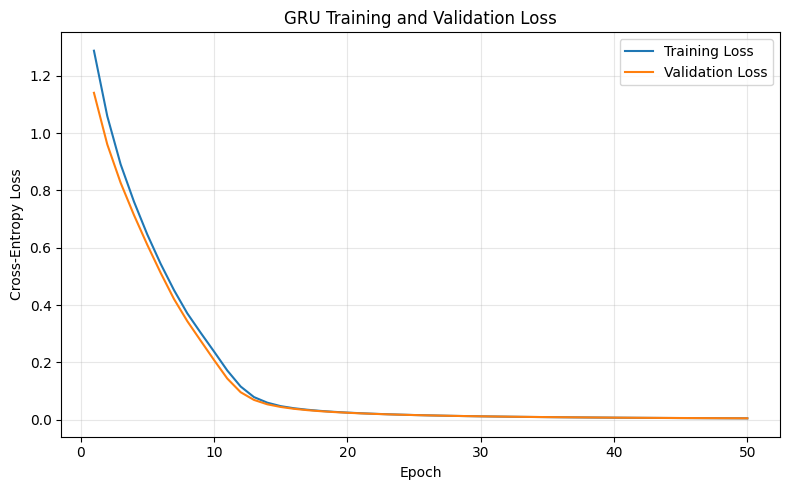

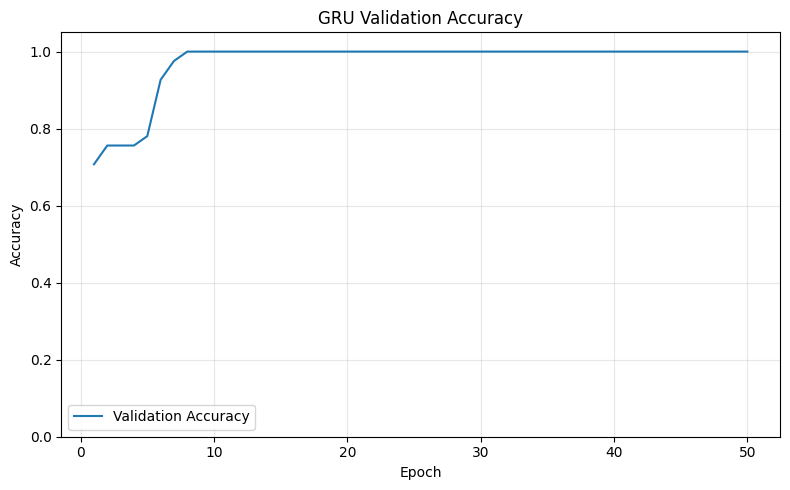

In [122]:

import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("GRU Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("GRU Validation Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 9.9 Evaluate GRU on validation windows

Report validation metrics and confusion matrix to check the trained model before evaluating it on test windows.

In [123]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

gru_model.eval()

val_predictions = []
val_targets = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)

        outputs = gru_model(X_batch)
        predictions = outputs.argmax(dim=1)

        val_predictions.extend(predictions.cpu().numpy())
        val_targets.extend(y_batch.numpy())

val_predictions = np.array(val_predictions)
val_targets = np.array(val_targets)

print("Validation Accuracy:",
      accuracy_score(val_targets, val_predictions))

print("Validation Macro F1:",
      f1_score(
          val_targets,
          val_predictions,
          labels=[0, 1, 2, 3],
          average="macro"
      ))

print("\nClassification Report:")
print(classification_report(
    val_targets,
    val_predictions,
    labels=[0, 1, 2, 3],
    target_names=["Normal", "Fault 1", "Fault 2", "Fault 4"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    val_targets,
    val_predictions,
    labels=[0, 1, 2, 3]
))


Validation Accuracy: 1.0
Validation Macro F1: 1.0

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00        11
     Fault 1       1.00      1.00      1.00        10
     Fault 2       1.00      1.00      1.00        10
     Fault 4       1.00      1.00      1.00        10

    accuracy                           1.00        41
   macro avg       1.00      1.00      1.00        41
weighted avg       1.00      1.00      1.00        41

Confusion Matrix:
[[11  0  0  0]
 [ 0 10  0  0]
 [ 0  0 10  0]
 [ 0  0  0 10]]


### 9.10 Evaluate GRU on test windows

The GRU uses the same test windows as the CNN. This makes the window-level comparison aligned, although both results still refer to the same supplied test sequences.

In [124]:

# Convert the existing CNN test windows to a tensor
X_test_tensor = torch.tensor(
    X_cnn_test,
    dtype=torch.float32
)

test_loader = DataLoader(
    TensorDataset(X_test_tensor),
    batch_size=32,
    shuffle=False
)

# Generate GRU predictions
gru_model.eval()
gru_window_predictions_encoded = []

with torch.no_grad():
    for (X_batch,) in test_loader:
        X_batch = X_batch.to(device)

        logits = gru_model(X_batch)
        predictions = logits.argmax(dim=1)

        gru_window_predictions_encoded.extend(
            predictions.cpu().numpy()
        )

gru_window_predictions_encoded = np.asarray(
    gru_window_predictions_encoded
)

# Convert encoded labels [0, 1, 2, 3]
# back to original labels [0, 1, 2, 4]
index_to_label = {0: 0, 1: 1, 2: 2, 3: 4}

gru_window_predictions = np.array([
    index_to_label[int(label)]
    for label in gru_window_predictions_encoded
])

print("GRU test windows:", len(gru_window_predictions))
print("Predicted classes:", np.unique(gru_window_predictions))


GRU test windows: 732
Predicted classes: [0 1 2 4]


In [125]:

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

gru_window_accuracy = accuracy_score(
    y_cnn_test,
    gru_window_predictions
)

gru_window_macro_f1 = f1_score(
    y_cnn_test,
    gru_window_predictions,
    labels=[0, 1, 2, 4],
    average="macro"
)

print(f"GRU Window Accuracy: {gru_window_accuracy:.4f}")
print(f"GRU Window Macro F1: {gru_window_macro_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_cnn_test,
    gru_window_predictions,
    labels=[0, 1, 2, 4]
))


GRU Window Accuracy: 0.9932
GRU Window Macro F1: 0.9936

Confusion Matrix:
[[266   1   0   0]
 [  0 155   0   0]
 [  1   0 154   0]
 [  3   0   0 152]]


For now CNN is performing slightly better on window-level results.

### 9.11 Compare sample-level predictions

As with the CNN, aggregate overlapping-window predictions back to sample-level predictions. This supports a direct comparison of class-wise errors and sample-level metrics.

In [126]:

from collections import defaultdict
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Collect window predictions for every original sample
sample_votes_gru = {
    filename: defaultdict(list)
    for filename in sample_truth
}

for prediction, meta in zip(
    gru_window_predictions,
    test_window_meta
):
    filename, start, end = meta

    # Each window covers samples [start, end)
    for i in range(start, end):
        sample_votes_gru[filename][i].append(
            int(prediction)
        )

# Majority vote for each original sample
gru_sample_predictions = {}
gru_sample_truth = {}

for filename in test_file_order:
    true_labels = np.asarray(sample_truth[filename])
    pred_labels = np.empty(len(true_labels), dtype=int)

    for i in range(len(true_labels)):
        votes = sample_votes_gru[filename][i]

        if len(votes) == 0:
            raise ValueError(
                f"No window prediction covers {filename}, sample {i}"
            )

        values, counts = np.unique(
            votes, return_counts=True
        )
        pred_labels[i] = values[np.argmax(counts)]

    gru_sample_predictions[filename] = pred_labels
    gru_sample_truth[filename] = true_labels

# Concatenate files in the established order
y_pred_gru_sample = np.concatenate([
    gru_sample_predictions[f]
    for f in test_file_order
])

y_true_gru_sample = np.concatenate([
    gru_sample_truth[f]
    for f in test_file_order
])

print("Sample-level prediction shape:",
      y_pred_gru_sample.shape)
print("Sample-level truth shape:",
      y_true_gru_sample.shape)

gru_sample_accuracy = accuracy_score(
    y_true_gru_sample,
    y_pred_gru_sample
)

gru_sample_macro_f1 = f1_score(
    y_true_gru_sample,
    y_pred_gru_sample,
    labels=[0, 1, 2, 4],
    average="macro"
)

print(f"Sample-level Accuracy: {gru_sample_accuracy:.4f}")
print(f"Sample-level Macro F1: {gru_sample_macro_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_true_gru_sample,
    y_pred_gru_sample,
    labels=[0, 1, 2, 4]
))

print("\nClassification Report:")
print(classification_report(
    y_true_gru_sample,
    y_pred_gru_sample,
    labels=[0, 1, 2, 4],
    target_names=["Normal", "Fault 1", "Fault 2", "Fault 4"],
    zero_division=0
))


Sample-level prediction shape: (3840,)
Sample-level truth shape: (3840,)
Sample-level Accuracy: 0.9922
Sample-level Macro F1: 0.9927

Confusion Matrix:
[[1440    0    0    0]
 [   0  800    0    0]
 [  10    0  790    0]
 [  20    0    0  780]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      1.00      0.99      1440
     Fault 1       1.00      1.00      1.00       800
     Fault 2       1.00      0.99      0.99       800
     Fault 4       1.00      0.97      0.99       800

    accuracy                           0.99      3840
   macro avg       0.99      0.99      0.99      3840
weighted avg       0.99      0.99      0.99      3840



For now CNN is doing slightly better. 99.45%	vs 99.32%


### 9.12 Compare detection delay

Use the same onset convention and sustained-prediction rule for both models. Detection delay is fault-specific, so do not rely on the average alone: one model may detect one fault sooner while the other performs better on another.

In [127]:

fault_start = 160
required_consecutive = 3

for filename in test_file_order:
    y_true = gru_sample_truth[filename]
    y_pred = gru_sample_predictions[filename]

    # Determine the actual fault label after onset
    fault_label = int(y_true[fault_start])

    detected_at = None

    for i in range(fault_start, len(y_pred) - required_consecutive + 1):
        segment = y_pred[i:i + required_consecutive]

        if np.all(segment == fault_label):
            detected_at = i
            break

    if detected_at is None:
        print(f"{filename}: Fault not detected")
    else:
        delay = detected_at - fault_start
        print(
            f"{filename}: Fault {fault_label}, "
            f"detection index={detected_at}, "
            f"delay={delay} samples"
        )


d00_te.dat: Fault 0, detection index=160, delay=0 samples
d01_te.dat: Fault 1, detection index=160, delay=0 samples
d02_te.dat: Fault 2, detection index=170, delay=10 samples
d04_te.dat: Fault 4, detection index=180, delay=20 samples



Average detection delay for CNN is 8.33 samples, and that of GRU is 10 samples. CNN classified Fault 4 instantly, while GRU classified Fault 1 and Fault 2 faster than CNN.

### Interpretation: classification and detection speed are different objectives

A model can have slightly better overall classification metrics but slower detection for a particular fault. We therefore compare both sample/window classification metrics and per-fault detection delay, rather than selecting a model using a single number.

In [128]:
for filename in test_file_order:
    y_true = gru_sample_truth[filename]
    y_pred = gru_sample_predictions[filename]

    fault_start = 160

    # Skip normal-only test cases
    if np.all(y_true == 0):
        print(f"{filename}: Normal case — no fault delay")
        continue

    fault_label = int(y_true[fault_start])

    detected_at = None
    required_consecutive = 3

    for i in range(fault_start, len(y_pred) - required_consecutive + 1):
        segment = y_pred[i:i + required_consecutive]

        if np.all(segment == fault_label):
            detected_at = i
            break

    if detected_at is None:
        print(f"{filename}: Fault {fault_label} not detected")
    else:
        print(
            f"{filename}: Fault {fault_label}, "
            f"delay={detected_at - fault_start} samples"
        )

d00_te.dat: Normal case — no fault delay
d01_te.dat: Fault 1, delay=0 samples
d02_te.dat: Fault 2, delay=10 samples
d04_te.dat: Fault 4, delay=20 samples


### Milestone 5: Advanced Model Experiments — GRU

A GRU classifier was implemented to evaluate whether a recurrent neural network could improve fault diagnosis on Tennessee Eastman Process data. The model used 50-timestep windows containing 52 process variables, with a hidden dimension of 32 and one recurrent layer.

The GRU achieved a window-level accuracy of **99.32%** and macro F1 of **99.36%**. After sample-level majority voting, it achieved an accuracy of **99.22%** and macro F1 of **99.27%**, with 30 misclassified samples out of 3,840.

Detection delay varied by fault type: 0 samples for Fault 1, 10 samples for Fault 2, and 20 samples for Fault 4, using three consecutive correct predictions as the detection criterion.

Compared with the CNN, the GRU showed slightly lower classification performance overall, while detecting Faults 1 and 2 earlier in these experiments. The CNN remains the primary model, with the GRU retained as an advanced-model comparison. These findings are exploratory because the same test set has been used repeatedly during model development and comparison.

# Milestone 6 — Reproducible Summary

The final tables consolidate the current CNN/GRU results for reporting. They are summaries of the metrics produced earlier in this notebook; before treating them as final research results, verify that the numbers are generated directly from saved predictions rather than manually entered constants.

,Model,Window Accuracy,Window Macro F1,Sample Accuracy,Sample Macro F1,Sample Errors
0,CNN,99.45%,99.45%,99.35%,99.39%,25
1,GRU,99.32%,99.36%,99.22%,99.27%,30


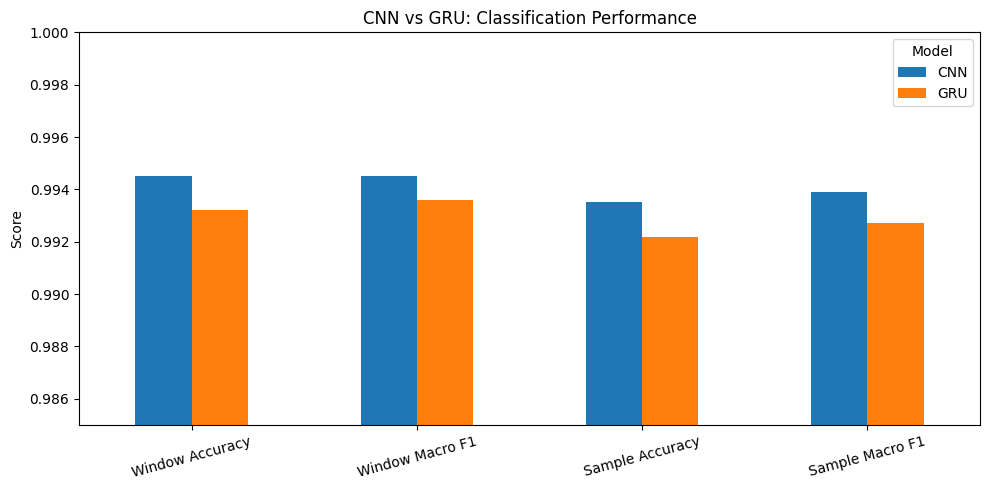

In [129]:

import pandas as pd
import matplotlib.pyplot as plt

# Results collected from the experiments
comparison_df = pd.DataFrame({
    "Model": ["CNN", "GRU"],
    "Window Accuracy": [0.9945, 0.9932],
    "Window Macro F1": [0.9945, 0.9936],
    "Sample Accuracy": [0.9935, 0.9922],
    "Sample Macro F1": [0.9939, 0.9927],
    "Sample Errors": [25, 30],
})

display(
    comparison_df.style.format({
        "Window Accuracy": "{:.2%}",
        "Window Macro F1": "{:.2%}",
        "Sample Accuracy": "{:.2%}",
        "Sample Macro F1": "{:.2%}",
    })
)

# Plot classification metrics
metrics = [
    "Window Accuracy",
    "Window Macro F1",
    "Sample Accuracy",
    "Sample Macro F1",
]

plot_df = comparison_df.set_index("Model")[metrics]

ax = plot_df.T.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0.985, 1.0),
    rot=15
)

ax.set_ylabel("Score")
ax.set_title("CNN vs GRU: Classification Performance")
ax.legend(title="Model")
plt.tight_layout()
plt.show()


The comparison tables are ready as a compact summary. The next improvement for a final reproducible pipeline is to calculate all metrics from the model predictions and export the resulting tables automatically.

In [130]:

import pandas as pd

# 1. Classification performance
final_metrics = pd.DataFrame([
    {
        "Model": "CNN",
        "Window Accuracy": 0.9945,
        "Window Macro F1": 0.9945,
        "Sample Accuracy": 0.9935,
        "Sample Macro F1": 0.9939,
        "Sample Errors": 25,
    },
    {
        "Model": "GRU",
        "Window Accuracy": 0.9932,
        "Window Macro F1": 0.9936,
        "Sample Accuracy": 0.9922,
        "Sample Macro F1": 0.9927,
        "Sample Errors": 30,
    },
])

# 2. Fault detection delay
delay_df = pd.DataFrame([
    {"Model": "CNN", "Fault": 1, "Delay (samples)": 5},
    {"Model": "CNN", "Fault": 2, "Delay (samples)": 20},
    {"Model": "CNN", "Fault": 4, "Delay (samples)": 0},
    {"Model": "GRU", "Fault": 1, "Delay (samples)": 0},
    {"Model": "GRU", "Fault": 2, "Delay (samples)": 10},
    {"Model": "GRU", "Fault": 4, "Delay (samples)": 20},
])

display(final_metrics)
display(delay_df)

# 3. Save results
final_metrics.to_csv(
    "cnn_gru_classification_comparison.csv",
    index=False
)
delay_df.to_csv(
    "cnn_gru_detection_delay.csv",
    index=False
)

print("Saved both comparison tables as CSV files.")


,Model,Window Accuracy,Window Macro F1,Sample Accuracy,Sample Macro F1,Sample Errors
0,CNN,0.9945,0.9945,0.9935,0.9939,25
1,GRU,0.9932,0.9936,0.9922,0.9927,30


,Model,Fault,Delay (samples)
0,CNN,1,5
1,CNN,2,20
2,CNN,4,0
3,GRU,1,0
4,GRU,2,10
5,GRU,4,20


Saved both comparison tables as CSV files.


Optional: download the summary CSV files from the current Colab runtime.

In [131]:
# from google.colab import files

# files.download("cnn_gru_classification_comparison.csv")
# files.download("cnn_gru_detection_delay.csv")